# PRCP-1027 / PRCP-1028 — Skin Disorder Prediction

**Project objective:** Analyse dermatology data and develop and evaluate machine-learning classification models.

**Important:** This is an educational machine-learning project, not a clinically validated diagnostic system.

## 1. Project Overview

### Problem statement
Develop a supervised machine-learning classification prototype using the UCI Dermatology dataset to predict one of six encoded skin-disorder classes from the supplied clinical, histopathological and demographic attributes.

### Objectives
1. Perform data-quality assessment and exploratory analysis.
2. Compare suitable classification algorithms using a consistent validation strategy.
3. Tune a selected model using training data only and evaluate it once on an untouched stratified test set.
4. Examine class-level errors and model feature importance.
5. Present cautious, workflow-oriented suggestions that may support clinical review, without positioning the model as a diagnostic authority.

### Scope and deliverables
The notebook addresses the institute's data-analysis, disease-class prediction and doctor-support objectives. Supporting deliverables include a model-comparison report, challenges report, project documentation, prediction module, tests and final PDF report.

**Project identifiers:** The institute problem statement is PRCP-1027; the project folder/archive identifier is PRCP-1028. Both are retained as supplied.

**Scope boundary:** This is an educational prototype trained and evaluated on a small historical dataset. No independent external validation, prospective clinical study, clinical safety assessment or deployment approval has been performed.


## 2. Dataset Source and Description

The project uses the Dermatology dataset from the UCI Machine Learning Repository. The source file is preserved in `data/raw/dataset_35_dermatology.csv` and its integrity is checked during project verification.

The dataset contains **366 records, 34 predictors and one six-class target**. The predictor groups comprise 10 scored clinical attributes, one binary family-history attribute, 22 histopathological attributes and one numerical Age attribute. The six target classes are mapped in the feature-dictionary cell.

The source data contains eight missing Age values and one Age value recorded as zero. These observations are retained in the source file; missing-value handling is performed within the modelling pipeline. The meaning of the zero-age record is not established by the supplied source and is not silently altered.

**Source:** UCI Machine Learning Repository — Dermatology Dataset: https://archive.ics.uci.edu/dataset/33/dermatology

**Citation:** Ilter, N. and Guvenir, H. (1998). *Dermatology*. UCI Machine Learning Repository. https://doi.org/10.24432/C5FK5P.


In [4]:
# SKIN_DATA_LOADING_CELL
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
import os
os.chdir(PROJECT_ROOT)

print("PROJECT ROOT:", PROJECT_ROOT)
print("WORKING DIRECTORY:", Path.cwd())
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "dataset_35_dermatology.csv"

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}")

df_raw = pd.read_csv(DATA_PATH, dtype={"Age": "string"})
df = df_raw.copy()
df["Age"] = pd.to_numeric(df["Age"].replace("?", np.nan), errors="coerce")

print("DATASET LOADED SUCCESSFULLY")
print("Dataset path:", DATA_PATH)
print("Original shape:", df_raw.shape)
print("Analysis shape:", df.shape)
print("Predictor count:", df.shape[1] - 1)
print("Target column: class")
print("Pandas version:", pd.__version__)
print("Scikit-learn version:", sklearn.__version__)
print("Age missing values:", df["Age"].isna().sum())
print("Age zero records:", (df["Age"] == 0).sum())

assert df.shape == (366, 35), "Unexpected dataset dimensions."
assert "class" in df.columns, "Target column is missing."
assert df["Age"].isna().sum() == 8, "Unexpected Age missing-value count."
assert (df["Age"] == 0).sum() == 1, "Unexpected Age zero count."

display(df.head())


PROJECT ROOT: C:\Rakesh Project\Detecting the Type of Skin Disorder\PRCP-1028-Skin-Disorder-Prediction
WORKING DIRECTORY: C:\Rakesh Project\Detecting the Type of Skin Disorder\PRCP-1028-Skin-Disorder-Prediction
DATASET LOADED SUCCESSFULLY
Dataset path: C:\Rakesh Project\Detecting the Type of Skin Disorder\PRCP-1028-Skin-Disorder-Prediction\data\raw\dataset_35_dermatology.csv
Original shape: (366, 35)
Analysis shape: (366, 35)
Predictor count: 34
Target column: class
Pandas version: 3.1.1
Scikit-learn version: 1.9.1
Age missing values: 8
Age zero records: 1


,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,...,disappearance_of_the_granular_layer,vacuolisation_and_damage_of_basal_layer,spongiosis,saw-tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_inflitrate,band-like_infiltrate,Age,class
0,2,2,0,3,0,0,0,0,1,0,...,0,0,3,0,0,0,1,0,55,2
1,3,3,3,2,1,0,0,0,1,1,...,0,0,0,0,0,0,1,0,8,1
2,2,1,2,3,1,3,0,3,0,0,...,0,2,3,2,0,0,2,3,26,3
3,2,2,2,0,0,0,0,0,3,2,...,3,0,0,0,0,0,3,0,40,1
4,2,3,2,2,2,2,0,2,0,0,...,2,3,2,3,0,0,2,3,45,3


### Dataset documentation and source

Source: UCI Machine Learning Repository — Dermatology Dataset
https://archive.ics.uci.edu/dataset/33/dermatology

Original dataset citation: Ilter, N. and Guvenir, H. (1998). Dermatology. UCI Machine Learning Repository. DOI: https://doi.org/10.24432/C5FK5P.

The dataset contains 10 scored clinical attributes, one binary family-history attribute, 22 histopathological attributes and one numerical age attribute. The target contains six disease classes.


In [5]:
# SKIN_FEATURE_DICTIONARY_CELL

clinical_features = [
    "erythema", "scaling", "definite_borders", "itching",
    "koebner_phenomenon", "polygonal_papules", "follicular_papules",
    "oral_mucosal_involvement", "knee_and_elbow_involvement",
    "scalp_involvement"
]

binary_features = ["family_history"]
demographic_features = ["Age"]

histopathological_features = [
    col for col in df.columns
    if col not in clinical_features + binary_features + demographic_features + ["class"]
]

class_labels = {
    1: "Psoriasis",
    2: "Seborrheic dermatitis",
    3: "Lichen planus",
    4: "Pityriasis rosea",
    5: "Chronic dermatitis",
    6: "Pityriasis rubra pilaris"
}

feature_dictionary = pd.DataFrame(
    [{"Feature": f, "Category": "Clinical (ordinal-coded)"} for f in clinical_features]
    + [{"Feature": f, "Category": "Binary"} for f in binary_features]
    + [{"Feature": f, "Category": "Histopathological (ordinal-coded)"} for f in histopathological_features]
    + [{"Feature": f, "Category": "Demographic (numerical)"} for f in demographic_features]
)

class_dictionary = pd.DataFrame({
    "Class Code": list(class_labels.keys()),
    "Disease": list(class_labels.values()),
    "Record Count": [int((df["class"] == code).sum()) for code in class_labels]
})

print("FEATURE GROUP COUNTS")
print("Scored clinical attributes:", len(clinical_features))
print("Binary attributes:", len(binary_features))
print("Histopathological attributes:", len(histopathological_features))
print("Demographic attributes:", len(demographic_features))
print("Total predictors:", len(feature_dictionary))

assert len(clinical_features) == 10
assert len(binary_features) == 1
assert len(histopathological_features) == 22
assert len(demographic_features) == 1
assert len(feature_dictionary) == 34

print("\nCOMPLETE FEATURE DICTIONARY")
display(feature_dictionary)

print("\nDISEASE CLASS DEFINITIONS")
display(class_dictionary)


FEATURE GROUP COUNTS
Scored clinical attributes: 10
Binary attributes: 1
Histopathological attributes: 22
Demographic attributes: 1
Total predictors: 34

COMPLETE FEATURE DICTIONARY


,Feature,Category
0,erythema,Clinical (ordinal-coded)
1,scaling,Clinical (ordinal-coded)
2,definite_borders,Clinical (ordinal-coded)
3,itching,Clinical (ordinal-coded)
4,koebner_phenomenon,Clinical (ordinal-coded)
5,polygonal_papules,Clinical (ordinal-coded)
6,follicular_papules,Clinical (ordinal-coded)
7,oral_mucosal_involvement,Clinical (ordinal-coded)
8,knee_and_elbow_involvement,Clinical (ordinal-coded)
9,scalp_involvement,Clinical (ordinal-coded)



DISEASE CLASS DEFINITIONS


,Class Code,Disease,Record Count
0,1,Psoriasis,112
1,2,Seborrheic dermatitis,61
2,3,Lichen planus,72
3,4,Pityriasis rosea,49
4,5,Chronic dermatitis,52
5,6,Pityriasis rubra pilaris,20


## 3. Data Quality Assessment

- Missing-value analysis
- Duplicate and duplicate-feature investigation
- Data types and valid ranges
- Age zero investigation
- Unusual and sparse feature values
- Data-quality decisions and justification

In [3]:
# SKIN_DATA_QUALITY_CELL

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")

assert df.shape == (366, 35), f"Unexpected dataset shape: {df.shape}"

X = df.drop(columns=["class"])
y = df["class"]

quality_table = pd.DataFrame({
    "Measure": [
        "Rows", "Columns", "Predictors", "Missing cells",
        "Rows with missing values", "Exact duplicate rows",
        "Duplicate predictor records", "Missing Age values",
        "Age equal to zero", "Constant predictors"
    ],
    "Result": [
        len(df), df.shape[1], X.shape[1],
        int(df.isna().sum().sum()),
        int(df.isna().any(axis=1).sum()),
        int(df.duplicated().sum()),
        int(df.duplicated(subset=X.columns).sum()),
        int(df["Age"].isna().sum()),
        int(df["Age"].eq(0).fillna(False).sum()),
        int((X.nunique(dropna=False) <= 1).sum())
    ]
})
print("DATA QUALITY SUMMARY")
display(quality_table)

missing_table = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage": (df.isna().mean() * 100).round(2)
})
missing_table = missing_table[missing_table["Missing Count"] > 0]
print("MISSING VALUE DETAILS")
display(missing_table)

print("MISSING AGE RECORDS")
display(df.loc[df["Age"].isna()])

print("AGE EQUAL TO ZERO RECORD")
display(df.loc[df["Age"].eq(0).fillna(False)])

class_summary = y.value_counts().sort_index().rename("Records").to_frame()
class_summary["Percentage"] = (class_summary["Records"] / len(df) * 100).round(2)
print("TARGET CLASS DISTRIBUTION")
display(class_summary)

print("Class imbalance ratio:",
      round(class_summary["Records"].max() / class_summary["Records"].min(), 2))

feature_profile = pd.DataFrame({
    "Data Type": X.dtypes.astype(str),
    "Unique Values": X.nunique(dropna=True),
    "Minimum": X.min(),
    "Maximum": X.max(),
    "Zero Count": X.eq(0).sum(),
    "Zero Percentage": (X.eq(0).mean() * 100).round(2),
    "Missing Count": X.isna().sum()
})
print("PREDICTOR PROFILE")
display(feature_profile)

age = df["Age"].dropna()
q1, q3 = age.quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
age_outliers = df.loc[
    df["Age"].notna() & ((df["Age"] < lower) | (df["Age"] > upper))
]
print("AGE IQR REVIEW")
display(pd.DataFrame({
    "Measure": ["Non-missing", "Minimum", "Median", "Maximum",
                "Q1", "Q3", "IQR", "Lower bound", "Upper bound",
                "IQR outlier count"],
    "Value": [len(age), age.min(), age.median(), age.max(),
              q1, q3, iqr, lower, upper, len(age_outliers)]
}))
display(age_outliers)

print("No records or features have been removed. Missing-age and zero-age treatment will be justified before modelling.")


DATA QUALITY SUMMARY


,Measure,Result
0,Rows,366
1,Columns,35
2,Predictors,34
3,Missing cells,8
4,Rows with missing values,8
5,Exact duplicate rows,0
6,Duplicate predictor records,0
7,Missing Age values,8
8,Age equal to zero,1
9,Constant predictors,0


MISSING VALUE DETAILS


,Missing Count,Missing Percentage
Age,8,2.19


MISSING AGE RECORDS


,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,...,disappearance_of_the_granular_layer,vacuolisation_and_damage_of_basal_layer,spongiosis,saw-tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_inflitrate,band-like_infiltrate,Age,class
33,2,2,1,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,<NA>,1
34,2,1,0,0,2,0,0,0,0,0,...,0,0,0,0,0,0,0,0,<NA>,4
35,2,2,1,2,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,<NA>,2
36,2,1,2,3,2,3,0,2,0,0,...,0,2,0,2,0,0,0,3,<NA>,3
262,2,1,0,2,0,0,0,0,0,0,...,0,0,2,0,0,0,3,0,<NA>,5
263,1,1,1,3,0,0,0,0,0,0,...,0,0,3,0,0,0,2,0,<NA>,5
264,1,1,0,2,0,0,0,0,1,0,...,0,0,2,0,0,0,3,0,<NA>,5
265,1,1,0,3,0,0,0,0,0,0,...,0,0,2,0,0,0,3,0,<NA>,5


... (6 outputs left out)

AGE IQR REVIEW


,Measure,Value
0,Non-missing,358.000
1,Minimum,0.000
2,Median,35.000
3,Maximum,75.000
4,Q1,25.000
5,Q3,49.750
6,IQR,24.750
7,Lower bound,-12.125
8,Upper bound,86.875
9,IQR outlier count,0.000


,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,...,disappearance_of_the_granular_layer,vacuolisation_and_damage_of_basal_layer,spongiosis,saw-tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_inflitrate,band-like_infiltrate,Age,class


No records or features have been removed. Missing-age and zero-age treatment will be justified before modelling.


### Data quality findings and decisions

The source contains 366 records and 35 columns (34 predictors plus the target). Eight values are missing in Age (2.19% of records); no other missing predictor values were identified in the verified dataset. There are no exact duplicate rows, no duplicate predictor vectors and no constant predictors. The target distribution is imbalanced: class 1 has 112 records and class 6 has 20, a largest-to-smallest ratio of 5.6:1.

The single Age = 0 record is retained because the dataset documentation available for this project does not establish whether it is a valid value or a coding issue. It is not treated as an outlier solely because it is unusual. Missing Age values are imputed inside the modelling pipeline, ensuring that imputation parameters are learned from training folds rather than from the full dataset.

Several predictors have high zero prevalence. A zero is a recorded feature code, not automatically a missing value. Sparse predictors are therefore profiled but not removed without evidence that they are uninformative.


## 4. Exploratory Data Analysis — Univariate

- Target distribution
- Age distribution
- Individual feature distributions
- Descriptive statistics
- Interpretation of findings

DESCRIPTIVE STATISTICS


,count,mean,std,min,25%,50%,75%,max
erythema,366.0,2.068306,0.664753,0.0,2.0,2.0,2.0,3.0
scaling,366.0,1.795082,0.701527,0.0,1.0,2.0,2.0,3.0
definite_borders,366.0,1.54918,0.907525,0.0,1.0,2.0,2.0,3.0
itching,366.0,1.36612,1.138299,0.0,0.0,1.0,2.0,3.0
koebner_phenomenon,366.0,0.63388,0.908016,0.0,0.0,0.0,1.0,3.0
polygonal_papules,366.0,0.448087,0.957327,0.0,0.0,0.0,0.0,3.0
follicular_papules,366.0,0.166667,0.570588,0.0,0.0,0.0,0.0,3.0
oral_mucosal_involvement,366.0,0.377049,0.834147,0.0,0.0,0.0,0.0,3.0
knee_and_elbow_involvement,366.0,0.614754,0.982979,0.0,0.0,0.0,1.0,3.0
scalp_involvement,366.0,0.519126,0.905639,0.0,0.0,0.0,1.0,3.0


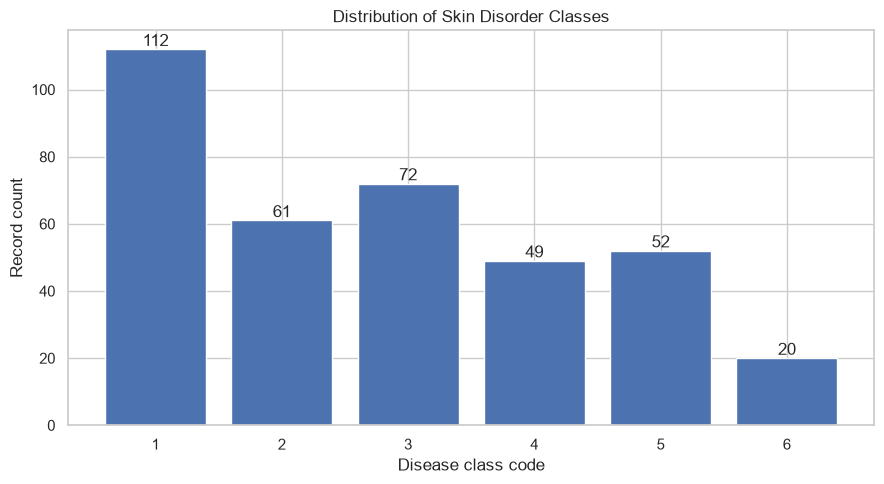

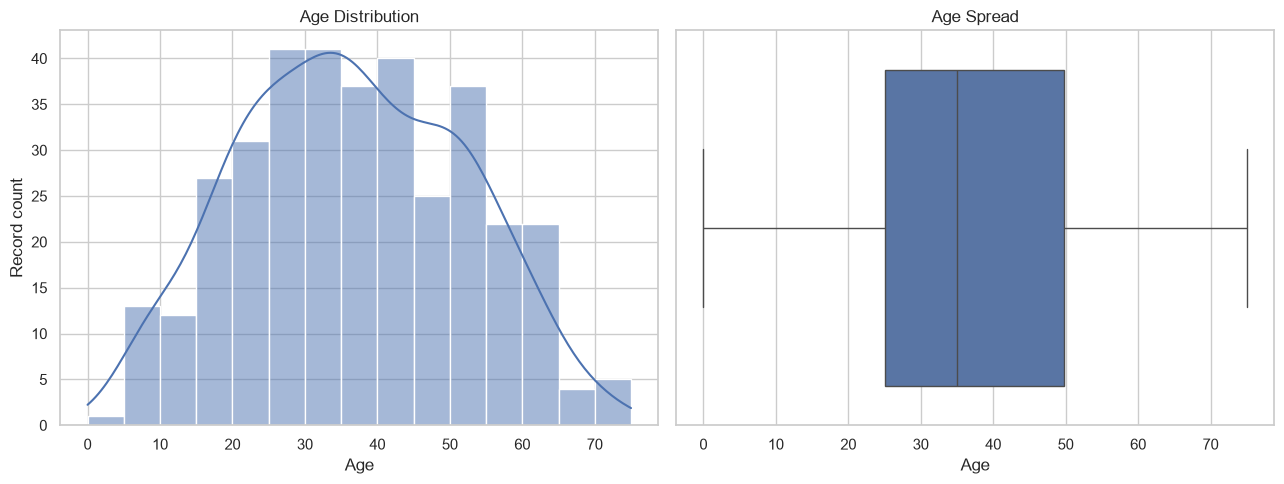

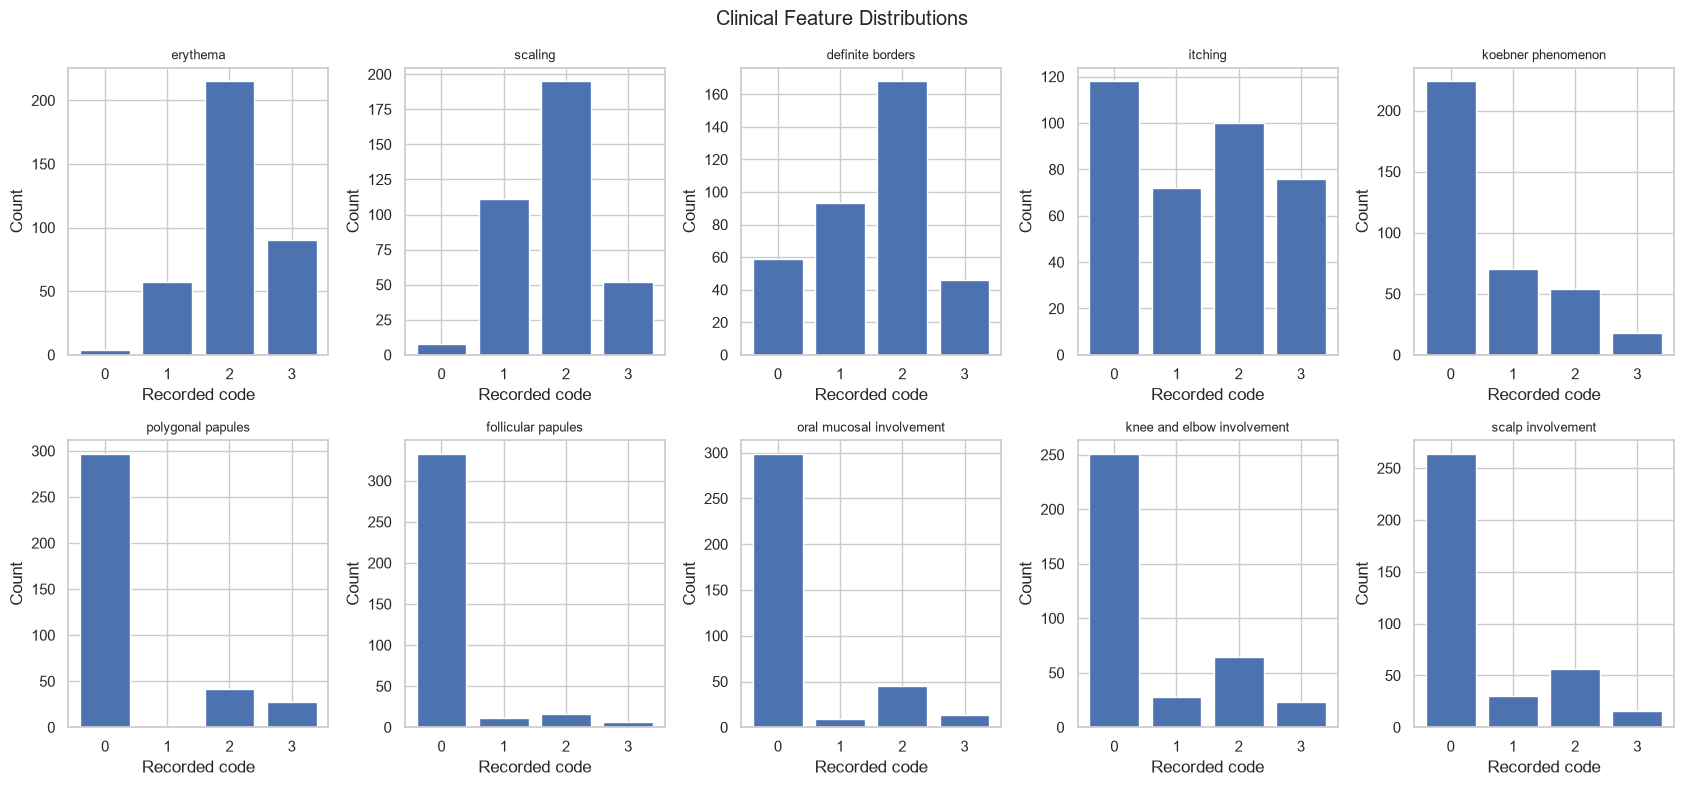

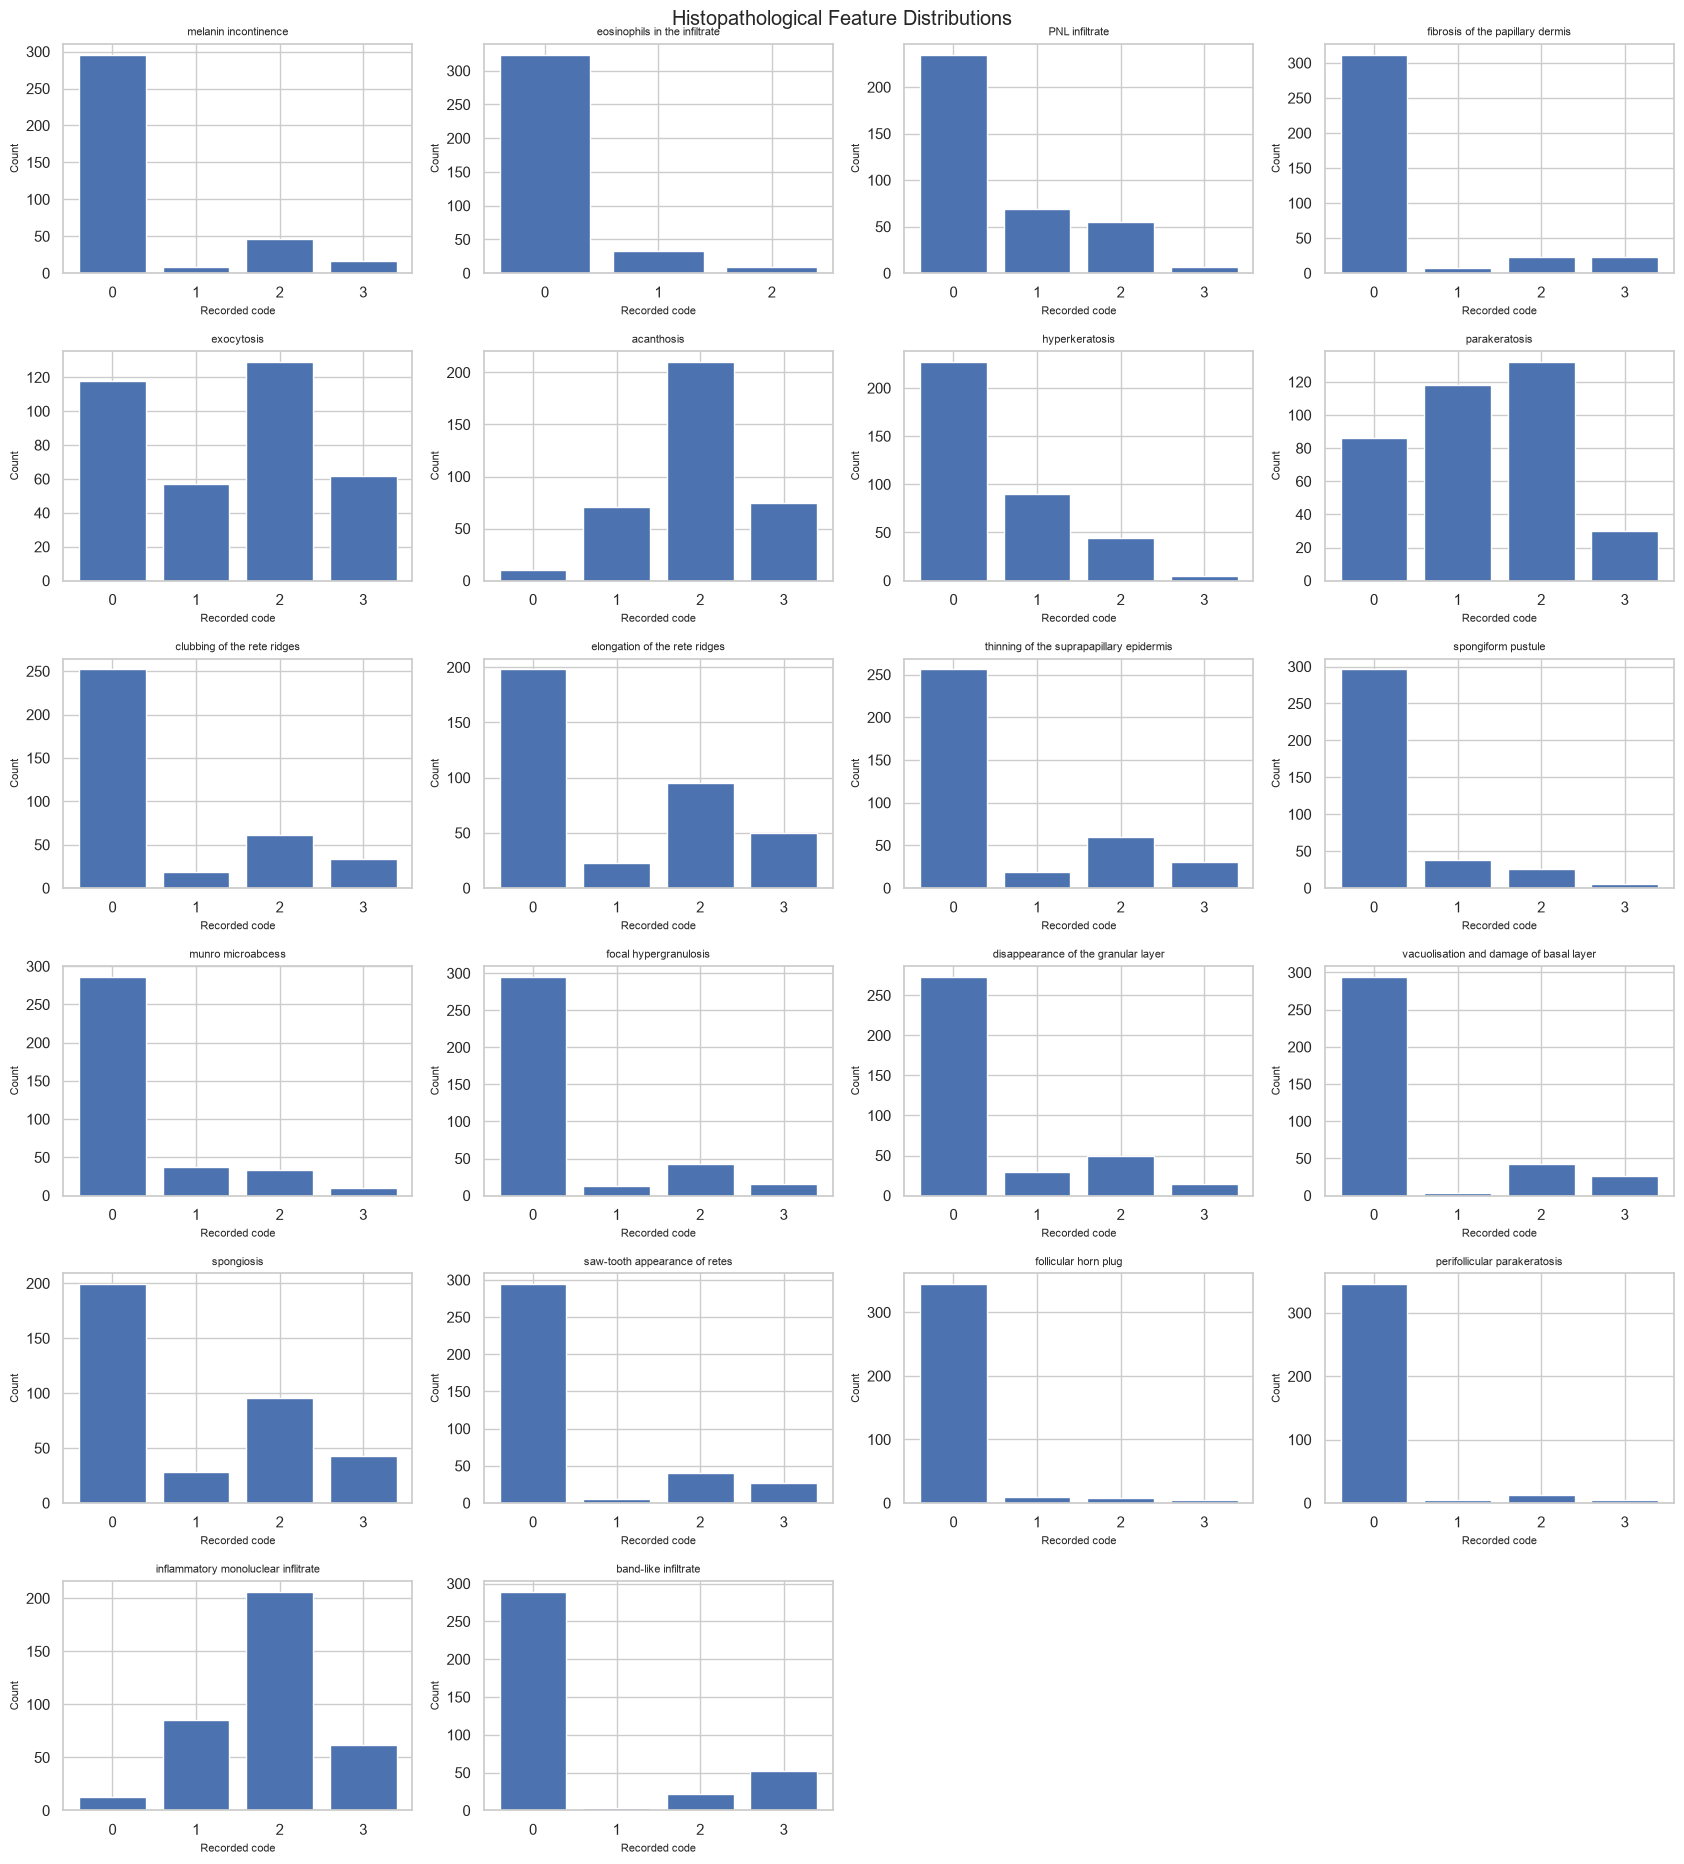

Interpretation: assess common and rare findings. Zero-heavy features may still contain useful information.


In [4]:
# SKIN_EDA_UNIVARIATE_CELL

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")

print("DESCRIPTIVE STATISTICS")
display(df.describe(include="all").T)

# Target distribution
counts = df["class"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(counts.index.astype(str), counts.values)
ax.set(title="Distribution of Skin Disorder Classes",
       xlabel="Disease class code", ylabel="Record count")
for bar, value in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, value + 1,
            str(value), ha="center")
plt.tight_layout()
plt.show()

# Age distribution
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.histplot(df["Age"].dropna(), bins=15, kde=True, ax=axes[0])
axes[0].set(title="Age Distribution", xlabel="Age", ylabel="Record count")
sns.boxplot(x=df["Age"], ax=axes[1])
axes[1].set(title="Age Spread", xlabel="Age")
plt.tight_layout()
plt.show()

# Clinical feature distributions
fig, axes = plt.subplots(2, 5, figsize=(17, 8))
for feature, ax in zip(clinical_features, axes.flat):
    values = df[feature].value_counts().sort_index()
    ax.bar(values.index.astype(str), values.values)
    ax.set_title(feature.replace("_", " "), fontsize=9)
    ax.set_xlabel("Recorded code")
    ax.set_ylabel("Count")
fig.suptitle("Clinical Feature Distributions")
plt.tight_layout()
plt.show()

# Histopathological feature distributions
fig, axes = plt.subplots(6, 4, figsize=(17, 19))
for feature, ax in zip(histopathological_features, axes.flat):
    values = df[feature].value_counts().sort_index()
    ax.bar(values.index.astype(str), values.values)
    ax.set_title(feature.replace("_", " "), fontsize=8)
    ax.set_xlabel("Recorded code", fontsize=8)
    ax.set_ylabel("Count", fontsize=8)
for ax in axes.flat[len(histopathological_features):]:
    ax.set_visible(False)
fig.suptitle("Histopathological Feature Distributions")
plt.tight_layout()
plt.show()

print("Interpretation: assess common and rare findings. Zero-heavy features may still contain useful information.")


### Univariate EDA interpretation

The target distribution is not uniform: Psoriasis (class 1) is the largest group (112/366; 30.60%), while Pityriasis rubra pilaris (class 6) is the smallest (20/366; 5.46%). This imbalance means accuracy alone could obscure weak performance on less frequent classes; macro-averaged metrics and balanced accuracy are therefore included later.

Age is available for 358 records. Its observed range is 0 to 75 years. The single zero value is flagged for source clarification rather than automatically removed. The feature-distribution plots show that recorded ordinal codes are not equally frequent across attributes. These distributions describe this dataset and should not be interpreted as population prevalence or disease severity.


## 5. Exploratory Data Analysis — Class-wise and Bivariate

- Age by disease class
- Clinical feature distributions by class
- Class-wise statistical summaries
- Feature relationships and correlation analysis
- Interpretation of findings

AGE SUMMARY BY DISEASE CLASS


,count,mean,median,min,max
class,,,,,
1,111,39.38,39.0,0,75
2,60,35.47,34.0,10,70
3,71,39.96,40.0,16,65
4,48,35.27,35.0,12,70
5,48,36.67,35.5,8,70
6,20,10.25,9.5,7,22


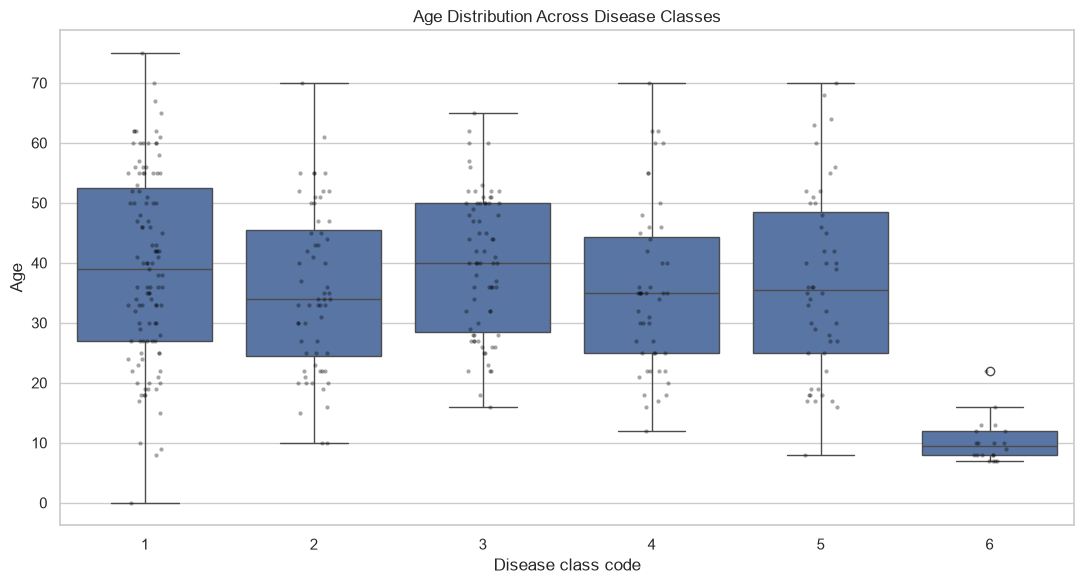

15 FEATURES WITH THE LARGEST BETWEEN-CLASS RANGE IN MEAN CODE


,Between-class mean range
band-like_infiltrate,2.722222
vacuolisation_and_damage_of_basal_layer,2.305556
saw-tooth_appearance_of_retes,2.291667
fibrosis_of_the_papillary_dermis,2.288462
polygonal_papules,2.277778
elongation_of_the_rete_ridges,2.258929
follicular_papules,2.200000
spongiosis,2.163934
clubbing_of_the_rete_ridges,2.116071
melanin_incontinence,2.055556


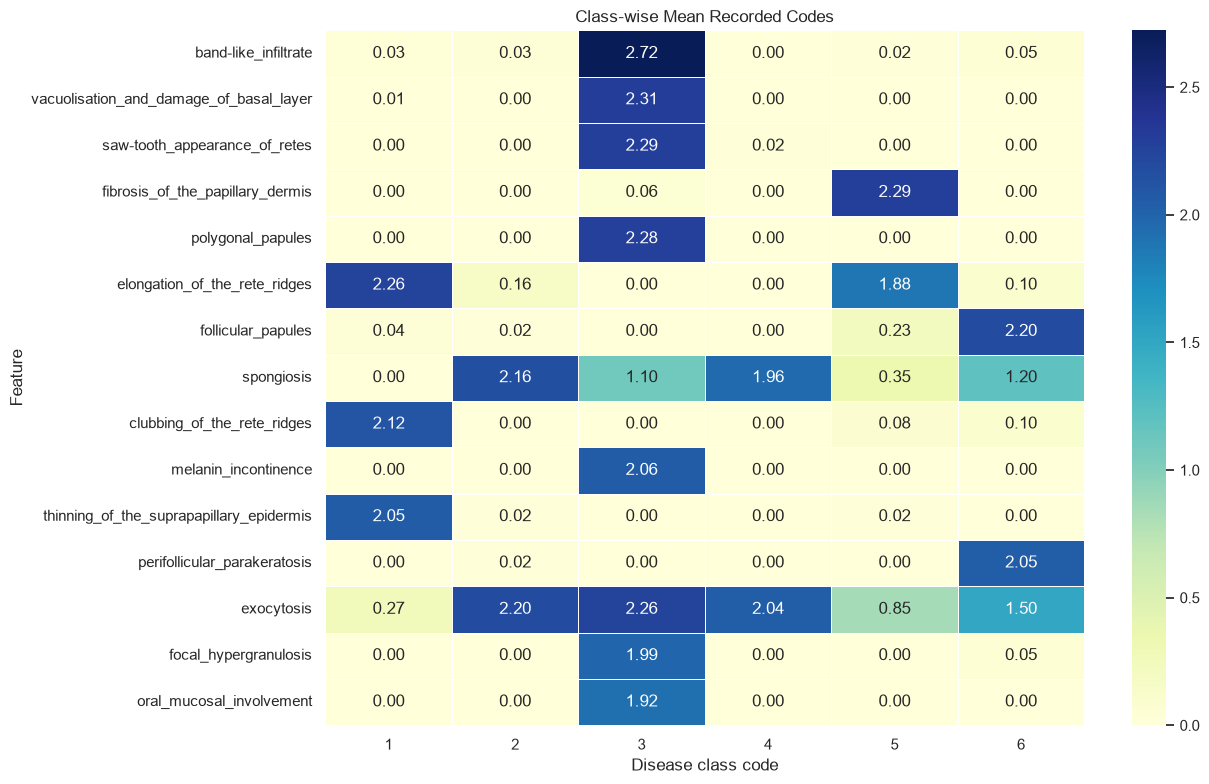

Mean ordinal codes are descriptive comparisons, not clinical severity or causal evidence.


In [5]:
# SKIN_EDA_CLASSWISE_CELL

age_by_class = (
    df.groupby("class", observed=True)["Age"]
      .agg(["count", "mean", "median", "min", "max"])
      .round(2)
)
print("AGE SUMMARY BY DISEASE CLASS")
display(age_by_class)

fig, ax = plt.subplots(figsize=(11, 6))
sns.boxplot(data=df, x="class", y="Age", ax=ax)
sns.stripplot(data=df, x="class", y="Age",
              color="black", alpha=0.35, size=3, ax=ax)
ax.set(title="Age Distribution Across Disease Classes",
       xlabel="Disease class code", ylabel="Age")
plt.tight_layout()
plt.show()

ordinal_features = clinical_features + histopathological_features
class_feature_means = df.groupby("class", observed=True)[ordinal_features].mean()

feature_separation = (
    class_feature_means.max(axis=0) - class_feature_means.min(axis=0)
).sort_values(ascending=False)

selected_features = feature_separation.head(15).index.tolist()
print("15 FEATURES WITH THE LARGEST BETWEEN-CLASS RANGE IN MEAN CODE")
display(feature_separation.head(15).rename("Between-class mean range").to_frame())

fig, ax = plt.subplots(figsize=(13, 8))
sns.heatmap(class_feature_means[selected_features].T,
            cmap="YlGnBu", annot=True, fmt=".2f",
            linewidths=0.4, ax=ax)
ax.set(title="Class-wise Mean Recorded Codes",
       xlabel="Disease class code", ylabel="Feature")
plt.tight_layout()
plt.show()

print("Mean ordinal codes are descriptive comparisons, not clinical severity or causal evidence.")


### Class-wise EDA interpretation

Age summaries and the class-wise feature-mean heatmap show differences in the recorded data between target classes. The largest between-class ranges in mean codes are useful for identifying candidate discriminating attributes for further model evaluation. However, these are descriptive comparisons on the full dataset: they do not establish causality, diagnostic thresholds or clinical severity.

Age availability differs slightly by class because eight records have missing Age values. Consequently, each class's age summary uses its available observations and should be read together with the reported non-missing count. The model evaluation, rather than these univariate differences alone, is used to assess predictive performance.


## 6. Multivariate Analysis and Feature Investigation

- Feature relationships
- Highly correlated feature investigation
- Sparse feature investigation
- Potentially informative features
- Analytical findings and implications

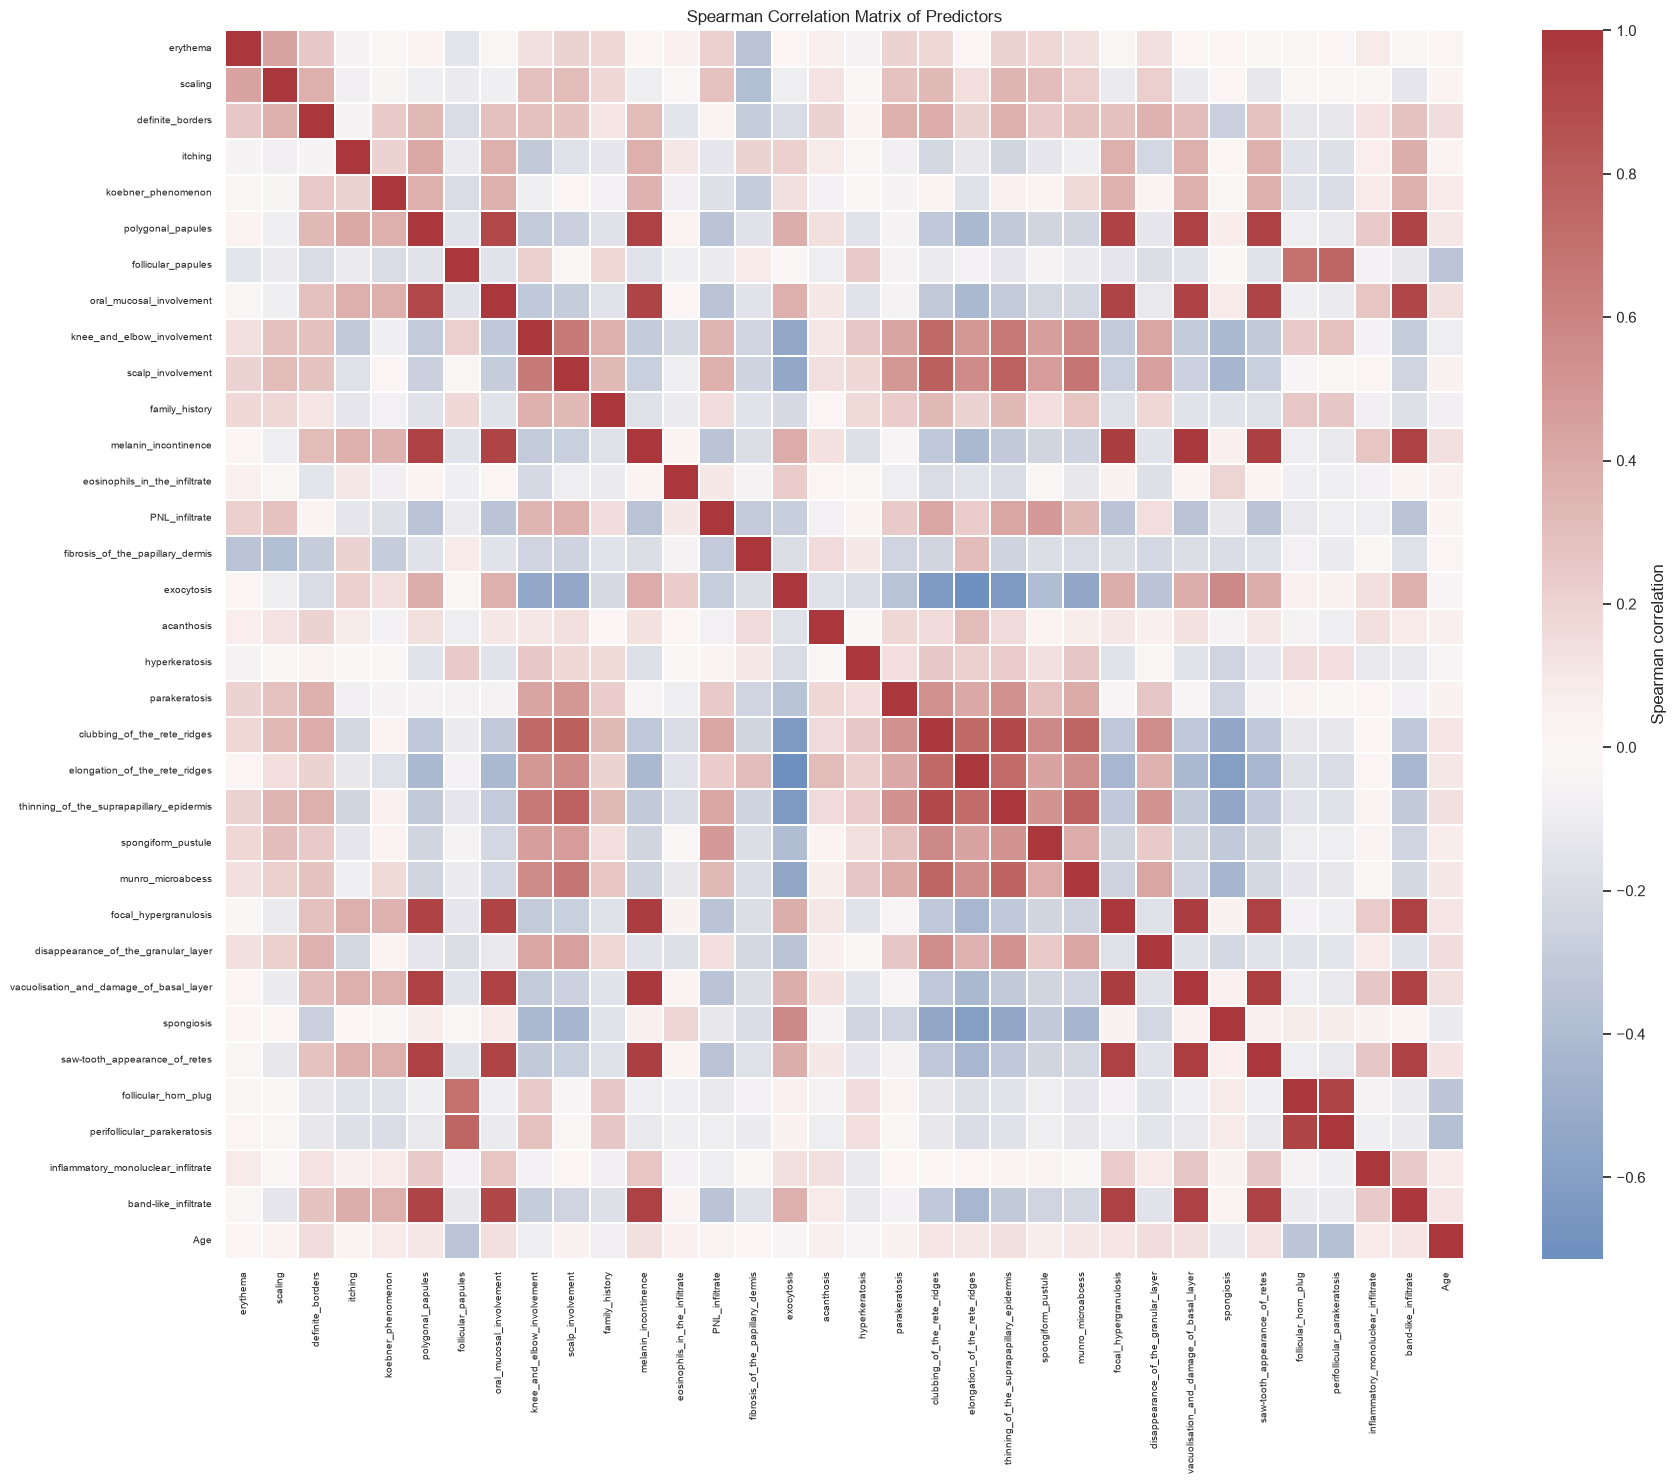

FEATURE PAIRS WITH ABSOLUTE SPEARMAN CORRELATION >= 0.70


,Feature 1,Feature 2,Spearman Correlation,Absolute Correlation
400,melanin_incontinence,vacuolisation_and_damage_of_basal_layer,0.980545,0.980545
842,focal_hypergranulosis,vacuolisation_and_damage_of_basal_layer,0.969554,0.969554
398,melanin_incontinence,focal_hypergranulosis,0.966728,0.966728
912,vacuolisation_and_damage_of_basal_layer,saw-tooth_appearance_of_retes,0.965544,0.965544
402,melanin_incontinence,saw-tooth_appearance_of_retes,0.957328,0.957328
181,polygonal_papules,melanin_incontinence,0.952971,0.952971
844,focal_hypergranulosis,saw-tooth_appearance_of_retes,0.952122,0.952122
916,vacuolisation_and_damage_of_basal_layer,band-like_infiltrate,0.950678,0.950678
196,polygonal_papules,vacuolisation_and_damage_of_basal_layer,0.947975,0.947975
984,saw-tooth_appearance_of_retes,band-like_infiltrate,0.947506,0.947506


FEATURE ZERO PREVALENCE


,Zero Count,Zero Percentage
perifollicular_parakeratosis,345,94.26
follicular_horn_plug,344,93.99
follicular_papules,333,90.98
eosinophils_in_the_infiltrate,324,88.52
family_history,320,87.43
fibrosis_of_the_papillary_dermis,312,85.25
oral_mucosal_involvement,299,81.69
polygonal_papules,297,81.15
melanin_incontinence,296,80.87
spongiform_pustule,296,80.87


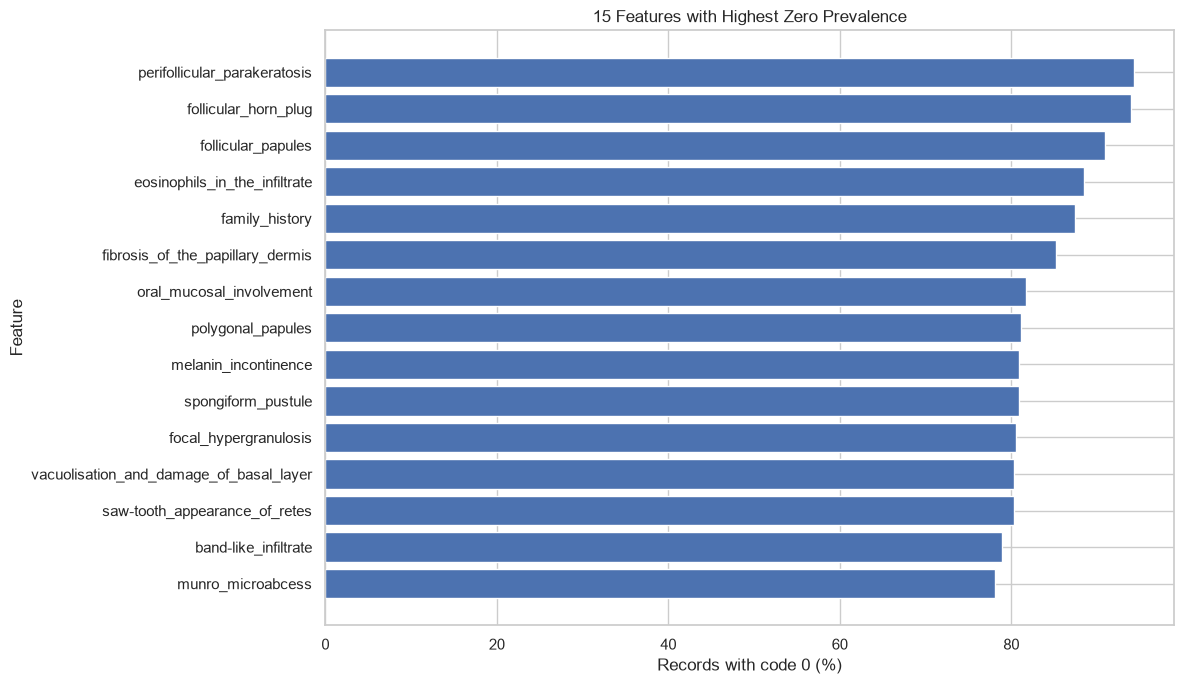

Interpretation:
- Correlation does not prove redundancy or causation.
- Overall correlation may reflect between-class differences.
- No feature is removed at this EDA stage.


In [6]:
# SKIN_EDA_MULTIVARIATE_CELL

X = df.drop(columns=["class"])

correlation = X.corr(method="spearman")
fig, ax = plt.subplots(figsize=(18, 15))
sns.heatmap(correlation, cmap="vlag", center=0,
            linewidths=0.15, ax=ax,
            cbar_kws={"label": "Spearman correlation"})
ax.set_title("Spearman Correlation Matrix of Predictors")
ax.tick_params(axis="x", labelrotation=90, labelsize=7)
ax.tick_params(axis="y", labelsize=7)
plt.tight_layout()
plt.show()

upper = correlation.where(
    np.triu(np.ones(correlation.shape), k=1).astype(bool)
)
pairs = upper.stack().rename("Spearman Correlation").reset_index()
pairs.columns = ["Feature 1", "Feature 2", "Spearman Correlation"]
pairs["Absolute Correlation"] = pairs["Spearman Correlation"].abs()
high_correlations = pairs[
    pairs["Absolute Correlation"] >= 0.70
].sort_values("Absolute Correlation", ascending=False)

print("FEATURE PAIRS WITH ABSOLUTE SPEARMAN CORRELATION >= 0.70")
display(high_correlations)

zero_profile = pd.DataFrame({
    "Zero Count": X.eq(0).sum(),
    "Zero Percentage": (X.eq(0).mean() * 100).round(2)
}).sort_values("Zero Percentage", ascending=False)

print("FEATURE ZERO PREVALENCE")
display(zero_profile)

fig, ax = plt.subplots(figsize=(12, 7))
top_sparse = zero_profile.head(15).sort_values("Zero Percentage")
ax.barh(top_sparse.index, top_sparse["Zero Percentage"])
ax.set(title="15 Features with Highest Zero Prevalence",
       xlabel="Records with code 0 (%)", ylabel="Feature")
plt.tight_layout()
plt.show()

print("Interpretation:")
print("- Correlation does not prove redundancy or causation.")
print("- Overall correlation may reflect between-class differences.")
print("- No feature is removed at this EDA stage.")


### Multivariate EDA interpretation

The Spearman matrix identifies several strongly associated predictor pairs. The strongest observed association is between vacuolisation/damage of the basal layer and melanin incontinence (approximately 0.981). Other high associations include vacuolisation with focal hypergranulosis (approximately 0.970), and focal hypergranulosis with melanin incontinence (approximately 0.967). These associations may reflect related findings or class structure; correlation alone is not sufficient reason to remove a predictor.

Some predictors are sparse: perifollicular parakeratosis is zero in approximately 94.3% of records, follicular horn plug in 94.0%, and follicular papules in 91.0%. A high zero proportion does not prove that a feature is useless, particularly where a non-zero finding may carry class information. The features are retained for model comparison and interpretation.


## 7. Data Preparation and Preprocessing

- Target and predictor separation
- Train/test split strategy
- Missing-value treatment
- Encoding and scaling decisions
- Class imbalance assessment
- Leakage prevention
- Reproducible preprocessing pipelines

In [6]:
# SKIN_PREPROCESSING_CELL

import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)

RANDOM_STATE = 42
TEST_SIZE = 0.20
N_SPLITS = 5

# Keep the original dataframe unchanged.
X = df.drop(columns=["class"]).copy()
y = df["class"].copy()

# Preserve the target distribution in both partitions.
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

cv_strategy = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE
)

# All imputation and scaling are fitted within each training fold.
# Scaling is useful for distance/margin-based models; tree models are
# largely invariant to monotonic scaling.
def make_pipeline(classifier):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", classifier)
    ])

print("DATA PARTITION SUMMARY")
print("Training records:", len(X_train))
print("Untouched test records:", len(X_test))
print("Training predictors:", X_train.shape[1])
print("Cross-validation folds:", N_SPLITS)

split_summary = pd.DataFrame({
    "Full Dataset": y.value_counts().sort_index(),
    "Training Set": y_train.value_counts().sort_index(),
    "Test Set": y_test.value_counts().sort_index()
}).fillna(0).astype(int)
split_summary.index.name = "Class"
display(split_summary)

assert set(X_train.index).isdisjoint(set(X_test.index))
assert len(X_train) + len(X_test) == len(X)
assert X_train.shape[1] == 34

os.makedirs("models", exist_ok=True)
os.makedirs("reports/model_evaluation", exist_ok=True)

print("Preprocessing strategy: median imputation inside pipelines.")
print("No test-set information is used to fit preprocessing.")
print("Age = 0 is retained pending source-level clarification.")


DATA PARTITION SUMMARY
Training records: 292
Untouched test records: 74
Training predictors: 34
Cross-validation folds: 5


,Full Dataset,Training Set,Test Set
Class,,,
1,112,89,23
2,61,49,12
3,72,57,15
4,49,39,10
5,52,42,10
6,20,16,4


Preprocessing strategy: median imputation inside pipelines.
No test-set information is used to fit preprocessing.
Age = 0 is retained pending source-level clarification.


## 8. Baseline Model

- Baseline strategy
- Baseline evaluation
- Interpretation

In [7]:
# SKIN_BASELINE_CELL

baseline_model = make_pipeline(
    DummyClassifier(strategy="most_frequent")
)

baseline_scores = cross_validate(
    baseline_model,
    X_train,
    y_train,
    cv=cv_strategy,
    scoring={
        "accuracy": "accuracy",
        "balanced_accuracy": "balanced_accuracy",
        "precision_macro": "precision_macro",
        "recall_macro": "recall_macro",
        "f1_macro": "f1_macro"
    },
    n_jobs=-1,
    return_train_score=False
)

baseline_results = {
    metric: float(np.mean(values))
    for metric, values in baseline_scores.items()
    if metric.startswith("test_")
}

baseline_table = pd.DataFrame([{
    "Model": "Dummy — most frequent",
    "CV Accuracy": baseline_results["test_accuracy"],
    "CV Balanced Accuracy": baseline_results["test_balanced_accuracy"],
    "CV Macro Precision": baseline_results["test_precision_macro"],
    "CV Macro Recall": baseline_results["test_recall_macro"],
    "CV Macro F1": baseline_results["test_f1_macro"]
}])

print("BASELINE PERFORMANCE — 5-FOLD STRATIFIED CV")
display(baseline_table.round(4))

print("The baseline predicts the most frequent training class.")
print("A useful classifier should outperform this reference, especially on macro F1 and balanced accuracy.")


BASELINE PERFORMANCE — 5-FOLD STRATIFIED CV


,Model,CV Accuracy,CV Balanced Accuracy,CV Macro Precision,CV Macro Recall,CV Macro F1
0,Dummy — most frequent,0.3048,0.1667,0.0508,0.1667,0.0779


The baseline predicts the most frequent training class.
A useful classifier should outperform this reference, especially on macro F1 and balanced accuracy.


### Baseline interpretation

The most-frequent DummyClassifier provides a deliberately simple reference that predicts only the most common training class. Its cross-validation Macro F1 is approximately 0.0779, compared with much higher scores from the evaluated supervised classifiers. This establishes that the later models learn class-discriminating patterns beyond the majority-class rule. The baseline is a reference point, not a clinically meaningful decision rule.


## 9. Model Development and Comparison

The following five supervised classifiers are compared using the same training partition and stratified cross-validation:

- Logistic Regression
- Decision Tree
- Random Forest
- Extra Trees
- Support Vector Machine with an RBF kernel

A most-frequent DummyClassifier is also evaluated as a baseline. K-Nearest Neighbours and Gradient Boosting are **not** part of the executed comparison and are therefore not claimed as evaluated models.

The comparison uses consistent folds and reports accuracy, balanced accuracy, macro precision, macro recall and macro F1. Macro F1 is particularly relevant because it gives each class equal weight despite the class imbalance.


Evaluating: Logistic Regression
Evaluating: Decision Tree
Evaluating: SVM (RBF)
Evaluating: Random Forest
Evaluating: Extra Trees

MODEL COMPARISON — TRAINING DATA ONLY


,Model,CV Accuracy,CV Balanced Accuracy,CV Macro Precision,CV Macro Recall,CV Macro F1
0,Extra Trees,0.9829,0.9805,0.9830,0.9805,0.9807
1,Logistic Regression,0.9794,0.9774,0.9785,0.9774,0.9768
2,SVM (RBF),0.9794,0.9774,0.9785,0.9774,0.9768
3,Random Forest,0.9726,0.9619,0.9766,0.9619,0.9664
4,Decision Tree,0.9521,0.9459,0.9594,0.9459,0.9484
5,Dummy — most frequent,0.3048,0.1667,0.0508,0.1667,0.0779


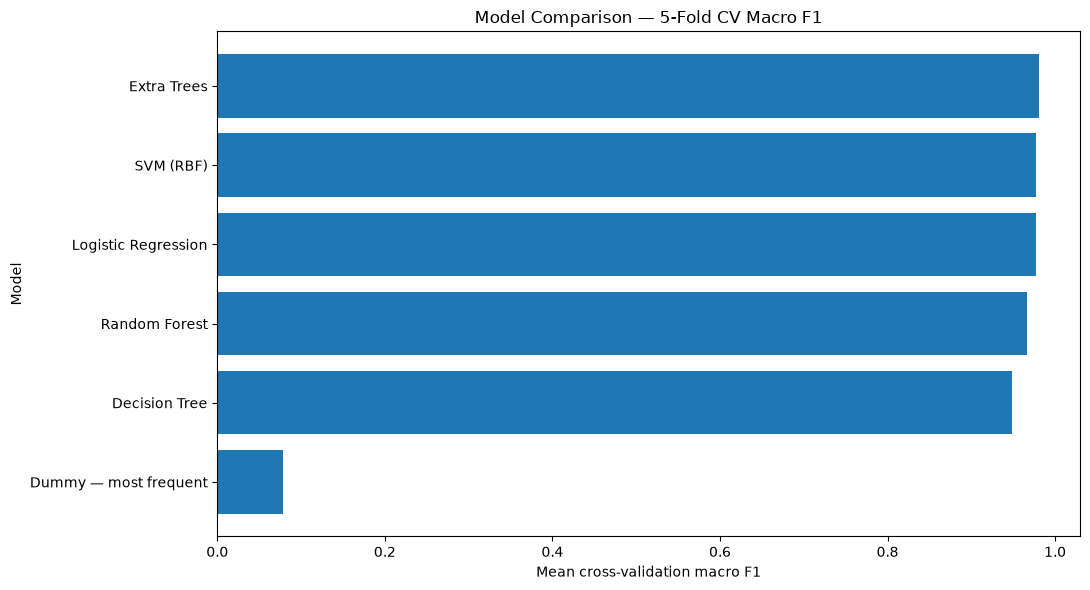

Comparison is based on training-set cross-validation.
The final test set has not been used for model selection.


In [8]:
# SKIN_MODEL_COMPARISON_CELL

models = {
    "Logistic Regression": make_pipeline(
        LogisticRegression(
            max_iter=5000,
            class_weight="balanced",
            random_state=RANDOM_STATE
        )
    ),
    "Decision Tree": make_pipeline(
        DecisionTreeClassifier(
            class_weight="balanced",
            random_state=RANDOM_STATE
        )
    ),
    "SVM (RBF)": make_pipeline(
        SVC(
            kernel="rbf",
            class_weight="balanced"
        )
    ),
    "Random Forest": make_pipeline(
        RandomForestClassifier(
            n_estimators=400,
            class_weight="balanced_subsample",
            random_state=RANDOM_STATE,
            n_jobs=-1
        )
    ),
    "Extra Trees": make_pipeline(
        ExtraTreesClassifier(
            n_estimators=400,
            class_weight="balanced",
            random_state=RANDOM_STATE,
            n_jobs=-1
        )
    )
}

scoring_metrics = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "precision_macro": "precision_macro",
    "recall_macro": "recall_macro",
    "f1_macro": "f1_macro"
}

comparison_rows = [{
    "Model": "Dummy — most frequent",
    "CV Accuracy": baseline_results["test_accuracy"],
    "CV Balanced Accuracy": baseline_results["test_balanced_accuracy"],
    "CV Macro Precision": baseline_results["test_precision_macro"],
    "CV Macro Recall": baseline_results["test_recall_macro"],
    "CV Macro F1": baseline_results["test_f1_macro"]
}]

cv_results_by_model = {}

for model_name, estimator in models.items():
    print("Evaluating:", model_name)
    result = cross_validate(
        estimator,
        X_train,
        y_train,
        cv=cv_strategy,
        scoring=scoring_metrics,
        n_jobs=-1,
        return_train_score=False
    )
    cv_results_by_model[model_name] = result

    comparison_rows.append({
        "Model": model_name,
        "CV Accuracy": np.mean(result["test_accuracy"]),
        "CV Balanced Accuracy": np.mean(result["test_balanced_accuracy"]),
        "CV Macro Precision": np.mean(result["test_precision_macro"]),
        "CV Macro Recall": np.mean(result["test_recall_macro"]),
        "CV Macro F1": np.mean(result["test_f1_macro"])
    })

comparison_table = pd.DataFrame(comparison_rows).sort_values(
    "CV Macro F1", ascending=False
).reset_index(drop=True)

print("\nMODEL COMPARISON — TRAINING DATA ONLY")
display(comparison_table.round(4))

fig, ax = plt.subplots(figsize=(11, 6))
plot_data = comparison_table.sort_values("CV Macro F1")
ax.barh(plot_data["Model"], plot_data["CV Macro F1"])
ax.set(title="Model Comparison — 5-Fold CV Macro F1",
       xlabel="Mean cross-validation macro F1", ylabel="Model")
plt.tight_layout()
plt.show()

comparison_table.to_csv(
    "reports/model_evaluation/model_comparison_cross_validation.csv",
    index=False
)

print("Comparison is based on training-set cross-validation.")
print("The final test set has not been used for model selection.")


### Model comparison interpretation

Extra Trees achieved the highest mean cross-validation Macro F1 among the evaluated candidates (approximately 0.9807), followed by Logistic Regression and the RBF SVM (approximately 0.9768 each). Random Forest and Decision Tree also outperformed the Dummy baseline. The differences among the strongest candidates are small relative to the limited dataset size, so the ranking should not be interpreted as proof of general superiority on new populations.

The comparison is performed on the training partition using the same stratified folds. The held-out test set is reserved for the final evaluation and is not used to select the model.


## 10. Model Validation and Hyperparameter Tuning

- Stratified cross-validation
- Validation strategy and justification
- Hyperparameter search
- Class-weight and imbalance-handling experiments where justified
- Validation results

In [10]:
# SKIN_TUNING_CELL

# Tune three competitive model families using training data only.
# The search objective is macro F1 so that every disease class contributes
# equally to the model-selection objective.

tuning_pipeline = make_pipeline(
    DummyClassifier(random_state=RANDOM_STATE)
)

parameter_grid = [
    {
        "classifier": [SVC(class_weight="balanced")],
        "classifier__kernel": ["rbf"],
        "classifier__C": [0.1, 1, 10],
        "classifier__gamma": ["scale", "auto"]
    },
    {
        "classifier": [RandomForestClassifier(
            class_weight="balanced_subsample",
            random_state=RANDOM_STATE,
            n_jobs=1
        )],
        "classifier__n_estimators": [300, 500],
        "classifier__max_features": ["sqrt", 0.7],
        "classifier__min_samples_leaf": [1, 2]
    },
    {
        "classifier": [ExtraTreesClassifier(
            class_weight="balanced",
            random_state=RANDOM_STATE,
            n_jobs=1
        )],
        "classifier__n_estimators": [300, 500],
        "classifier__max_features": ["sqrt", 0.7],
        "classifier__min_samples_leaf": [1, 2]
    }
]

grid_search = GridSearchCV(
    estimator=tuning_pipeline,
    param_grid=parameter_grid,
    scoring="f1_macro",
    cv=cv_strategy,
    n_jobs=-1,
    refit=True,
    return_train_score=True,
    error_score="raise"
)

print("Starting hyperparameter search.")
print("Candidate families: SVM, Random Forest and Extra Trees.")
grid_search.fit(X_train, y_train)

print("\nBEST CROSS-VALIDATED MACRO F1:")
print(round(grid_search.best_score_, 4))

print("\nBEST PARAMETERS:")
display(pd.DataFrame(
    [{"Parameter": k, "Value": str(v)}
     for k, v in grid_search.best_params_.items()]
))

tuning_results = pd.DataFrame(grid_search.cv_results_)
tuning_results = tuning_results.sort_values(
    "rank_test_score"
)[[
    "rank_test_score", "mean_test_score", "std_test_score",
    "mean_train_score", "params"
]].head(15)

print("TOP 15 TUNING CONFIGURATIONS")
display(tuning_results)

tuning_results.to_csv(
    "reports/model_evaluation/hyperparameter_search_top15.csv",
    index=False
)

best_model = grid_search.best_estimator_
print("Best estimator selected using training data only.")


Starting hyperparameter search.
Candidate families: SVM, Random Forest and Extra Trees.

BEST CROSS-VALIDATED MACRO F1:
0.9845

BEST PARAMETERS:


,Parameter,Value
0,classifier,"ExtraTreesClassifier(class_weight='balanced', ..."
1,classifier__max_features,0.7
2,classifier__min_samples_leaf,1
3,classifier__n_estimators,300


TOP 15 TUNING CONFIGURATIONS


,rank_test_score,mean_test_score,std_test_score,mean_train_score,params
18,1,0.984477,0.014563,1.000000,{'classifier': ExtraTreesClassifier(class_weig...
19,1,0.984477,0.014563,1.000000,{'classifier': ExtraTreesClassifier(class_weig...
15,3,0.980673,0.000353,1.000000,{'classifier': ExtraTreesClassifier(class_weig...
14,3,0.980673,0.000353,1.000000,{'classifier': ExtraTreesClassifier(class_weig...
16,3,0.980673,0.000353,1.000000,{'classifier': ExtraTreesClassifier(class_weig...
17,3,0.980673,0.000353,1.000000,{'classifier': ExtraTreesClassifier(class_weig...
21,7,0.980667,0.012323,1.000000,{'classifier': ExtraTreesClassifier(class_weig...
20,7,0.980667,0.012323,1.000000,{'classifier': ExtraTreesClassifier(class_weig...
3,9,0.976766,0.014549,0.982787,"{'classifier': SVC(class_weight='balanced'), '..."
2,9,0.976766,0.014549,0.982787,"{'classifier': SVC(class_weight='balanced'), '..."


Best estimator selected using training data only.


### Tuning and validation interpretation

Hyperparameter search optimises Macro F1 using stratified cross-validation on the training partition only. The selected Extra Trees configuration uses 300 trees, `max_features=0.7`, `min_samples_leaf=1` and balanced class weights. Its best mean cross-validation Macro F1 is approximately 0.9845 (standard deviation approximately 0.0146).

The mean training Macro F1 for the selected configuration is 1.0. This perfect training-fold score alongside a lower cross-validation score is a warning sign for possible overfitting; it is not evidence that the model will achieve perfect performance on unseen data. The untouched test set provides a separate, limited estimate of generalisation.


## 11. Final Model Selection and Test Evaluation

- Model selection justification
- Untouched test-set evaluation
- Accuracy, precision, recall and F1
- Macro and weighted averages
- Balanced accuracy
- Per-class metrics
- Confusion matrix

FINAL HOLDOUT TEST METRICS


,Metric,Test Result
0,Accuracy,0.9459
1,Balanced Accuracy,0.9472
2,Macro Precision,0.9237
3,Macro Recall,0.9472
4,Macro F1,0.9288
5,Weighted F1,0.9451


CLASSIFICATION REPORT


,precision,recall,f1-score,support
Psoriasis,1.0000,1.0000,1.0000,23.0000
Seborrheic dermatitis,1.0000,0.7500,0.8571,12.0000
Lichen planus,1.0000,0.9333,0.9655,15.0000
Pityriasis rosea,0.8333,1.0000,0.9091,10.0000
Chronic dermatitis,0.9091,1.0000,0.9524,10.0000
Pityriasis rubra pilaris,0.8000,1.0000,0.8889,4.0000
accuracy,0.9459,0.9459,0.9459,0.9459
macro avg,0.9237,0.9472,0.9288,74.0000
weighted avg,0.9544,0.9459,0.9451,74.0000


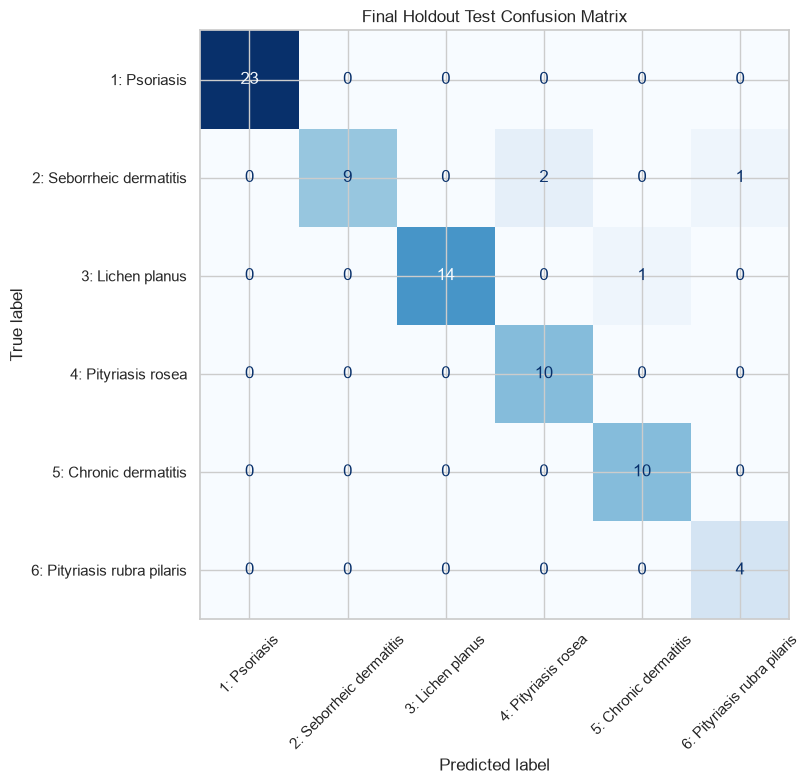

SAVED MODEL: models/skin_disorder_best_model.joblib
SAVED: final test metrics, class report and test predictions.
IMPORTANT: The test set contains only a small number of examples for the rarest class.
Interpret per-class test metrics cautiously; this is not clinical validation.


In [11]:
# SKIN_FINAL_EVALUATION_CELL

# This is the first use of the untouched test set.
y_test_pred = best_model.predict(X_test)

test_metrics = {
    "Accuracy": accuracy_score(y_test, y_test_pred),
    "Balanced Accuracy": balanced_accuracy_score(y_test, y_test_pred),
    "Macro Precision": precision_score(
        y_test, y_test_pred, average="macro", zero_division=0
    ),
    "Macro Recall": recall_score(
        y_test, y_test_pred, average="macro", zero_division=0
    ),
    "Macro F1": f1_score(
        y_test, y_test_pred, average="macro", zero_division=0
    ),
    "Weighted F1": f1_score(
        y_test, y_test_pred, average="weighted", zero_division=0
    )
}

test_metrics_table = pd.DataFrame(
    [{"Metric": k, "Test Result": v} for k, v in test_metrics.items()]
)

print("FINAL HOLDOUT TEST METRICS")
display(test_metrics_table.round(4))

print("CLASSIFICATION REPORT")
report = classification_report(
    y_test,
    y_test_pred,
    labels=sorted(class_labels.keys()),
    target_names=[class_labels[k] for k in sorted(class_labels)],
    output_dict=True,
    zero_division=0
)
report_table = pd.DataFrame(report).T
display(report_table.round(4))

fig, ax = plt.subplots(figsize=(10, 8))
cm = confusion_matrix(y_test, y_test_pred, labels=sorted(class_labels.keys()))
display_labels = [
    f"{code}: {class_labels[code]}" for code in sorted(class_labels)
]
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=display_labels
)
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
ax.set_title("Final Holdout Test Confusion Matrix")
plt.tight_layout()
plt.show()

test_metrics_table.to_csv(
    "reports/model_evaluation/final_test_metrics.csv",
    index=False
)
report_table.to_csv(
    "reports/model_evaluation/final_classification_report.csv"
)

# Save the fitted pipeline, including preprocessing.
joblib.dump(best_model, "models/skin_disorder_best_model.joblib")

# Save test predictions for later error analysis.
test_predictions = pd.DataFrame({
    "Actual Class": y_test,
    "Predicted Class": y_test_pred
}, index=y_test.index)
test_predictions["Actual Disease"] = test_predictions["Actual Class"].map(class_labels)
test_predictions["Predicted Disease"] = test_predictions["Predicted Class"].map(class_labels)
test_predictions["Correct"] = (
    test_predictions["Actual Class"] == test_predictions["Predicted Class"]
)
test_predictions.to_csv(
    "reports/model_evaluation/final_test_predictions.csv",
    index=True
)

print("SAVED MODEL: models/skin_disorder_best_model.joblib")
print("SAVED: final test metrics, class report and test predictions.")
print("IMPORTANT: The test set contains only a small number of examples for the rarest class.")
print("Interpret per-class test metrics cautiously; this is not clinical validation.")


### Final test-set interpretation

The final stratified holdout contains 74 records. The model achieved 0.9459 accuracy, 0.9472 balanced accuracy, 0.9237 macro precision, 0.9472 macro recall and 0.9288 macro F1 (weighted F1: 0.9451). Balanced accuracy and macro metrics are reported alongside accuracy to reflect performance across all six classes.

The six disease-class supports sum to 74. Class 6 has only four test examples; its observed scores are therefore highly uncertain. The test set contains four misclassifications. In particular, two Seborrheic dermatitis records were predicted as Pityriasis rosea, one Seborrheic dermatitis record as Pityriasis rubra pilaris, and one Lichen planus record as Chronic dermatitis. These errors show why the output cannot be used as an autonomous diagnosis.


## 12. Model Interpretation and Error Analysis

- Feature importance or suitable model explanations
- Class-level performance analysis
- Misclassification investigation
- Model limitations and reliability

MODEL INTERPRETATION
Selected classifier: ExtraTreesClassifier
PERMUTATION FEATURE IMPORTANCE — TEST SET


,Feature,Mean Importance,Importance Std
14,fibrosis_of_the_papillary_dermis,0.2219,0.0267
30,perifollicular_parakeratosis,0.1063,0.0304
4,koebner_phenomenon,0.0753,0.0313
25,disappearance_of_the_granular_layer,0.0682,0.0276
19,clubbing_of_the_rete_ridges,0.0214,0.0147
27,spongiosis,0.0081,0.0060
21,thinning_of_the_suprapapillary_epidermis,0.0066,0.0074
20,elongation_of_the_rete_ridges,0.0028,0.0109
17,hyperkeratosis,0.0021,0.0055
26,vacuolisation_and_damage_of_basal_layer,0.0020,0.0094


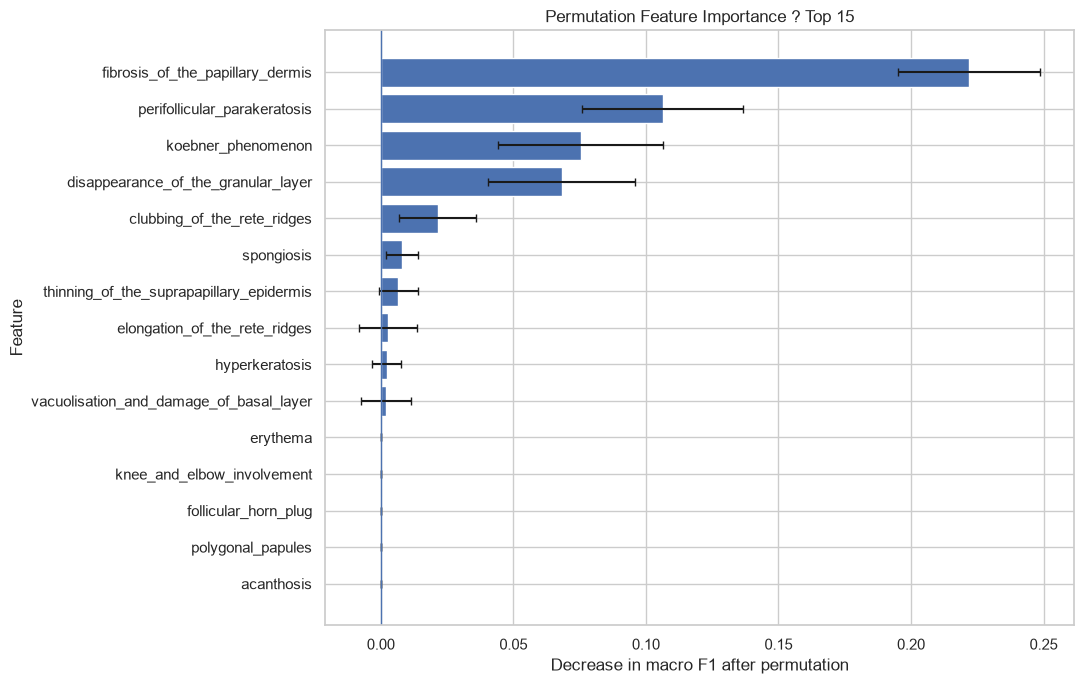

Interpretation cautions:
- Importance measures model reliance, not medical causation.
- Correlated features can share or mask importance.
- Negative or near-zero importance does not prove a feature is clinically irrelevant.
- Estimates are exploratory because the held-out test set is small.

TEST SET PREDICTION SUMMARY
Total test records: 74
Correct predictions: 70
Incorrect predictions: 4
Test accuracy: 0.9459

MISCLASSIFIED RECORDS


,Actual Class,Predicted Class,Actual Disease,Predicted Disease,Correct
28,2,6,Seborrheic dermatitis,Pityriasis rubra pilaris,False
143,3,5,Lichen planus,Chronic dermatitis,False
140,2,4,Seborrheic dermatitis,Pityriasis rosea,False
43,2,4,Seborrheic dermatitis,Pityriasis rosea,False



MOST FREQUENT CLASS CONFUSIONS


,Actual Disease,Predicted Disease,Error Count
1,Seborrheic dermatitis,Pityriasis rosea,2
0,Lichen planus,Chronic dermatitis,1
2,Seborrheic dermatitis,Pityriasis rubra pilaris,1



CLASS-WISE TEST PERFORMANCE


,precision,recall,f1-score,support
Psoriasis,1.0000,1.0000,1.0000,23.0
Seborrheic dermatitis,1.0000,0.7500,0.8571,12.0
Lichen planus,1.0000,0.9333,0.9655,15.0
Pityriasis rosea,0.8333,1.0000,0.9091,10.0
Chronic dermatitis,0.9091,1.0000,0.9524,10.0
Pityriasis rubra pilaris,0.8000,1.0000,0.8889,4.0


In [12]:
# SKIN_INTERPRETATION_CELL

from sklearn.inspection import permutation_importance
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("MODEL INTERPRETATION")
print("Selected classifier:", type(best_model.named_steps["classifier"]).__name__)

# Permutation importance on the held-out test set.
# This is an exploratory interpretation, not another model-selection step.
# With a small test set, importance estimates may be unstable.
permutation_result = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring="f1_macro",
    n_repeats=30,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

importance_table = pd.DataFrame({
    "Feature": X_test.columns,
    "Mean Importance": permutation_result.importances_mean,
    "Importance Std": permutation_result.importances_std
}).sort_values("Mean Importance", ascending=False)

print("PERMUTATION FEATURE IMPORTANCE — TEST SET")
display(importance_table.head(20).round(4))

importance_table.to_csv(
    "reports/model_evaluation/permutation_feature_importance.csv",
    index=False
)

top_importance = importance_table.head(15).sort_values("Mean Importance")
fig, ax = plt.subplots(figsize=(11, 7))
ax.barh(top_importance["Feature"], top_importance["Mean Importance"],
        xerr=top_importance["Importance Std"], capsize=3)
ax.axvline(0, linewidth=1)
ax.set(title="Permutation Feature Importance — Top 15",
       xlabel="Decrease in macro F1 after permutation",
       ylabel="Feature")
plt.tight_layout()
plt.show()

print("Interpretation cautions:")
print("- Importance measures model reliance, not medical causation.")
print("- Correlated features can share or mask importance.")
print("- Negative or near-zero importance does not prove a feature is clinically irrelevant.")
print("- Estimates are exploratory because the held-out test set is small.")

# Detailed misclassification analysis
test_predictions = test_predictions.copy()
misclassified = test_predictions.loc[~test_predictions["Correct"]].copy()

print("\nTEST SET PREDICTION SUMMARY")
print("Total test records:", len(test_predictions))
print("Correct predictions:", int(test_predictions["Correct"].sum()))
print("Incorrect predictions:", len(misclassified))
print("Test accuracy:", round(accuracy_score(y_test, y_test_pred), 4))

print("\nMISCLASSIFIED RECORDS")
if misclassified.empty:
    print("No test records were misclassified.")
else:
    display(misclassified)

    misclassified.to_csv(
        "reports/model_evaluation/misclassified_test_records.csv",
        index=True
    )

# Actual-to-predicted class error pairs
if not misclassified.empty:
    error_pairs = (
        misclassified.groupby(
            ["Actual Disease", "Predicted Disease"]
        ).size().reset_index(name="Error Count")
        .sort_values("Error Count", ascending=False)
    )
else:
    error_pairs = pd.DataFrame(
        columns=["Actual Disease", "Predicted Disease", "Error Count"]
    )

print("\nMOST FREQUENT CLASS CONFUSIONS")
display(error_pairs)
error_pairs.to_csv(
    "reports/model_evaluation/class_confusion_pairs.csv",
    index=False
)

print("\nCLASS-WISE TEST PERFORMANCE")
display(report_table.loc[
    [class_labels[k] for k in sorted(class_labels)]
].round(4))


### Interpretation and error-analysis limitations

Permutation importance ranks features by the reduction in the selected scoring measure when a feature is permuted on the held-out test sample. In this run, fibrosis of the papillary dermis has the largest mean importance (approximately 0.2219), followed by perifollicular parakeratosis (0.1063), Koebner phenomenon (0.0753) and disappearance of the granular layer (0.0682).

These estimates are dependent on this fitted model and this small test sample. Correlated predictors can share or obscure importance, and the standard deviations indicate variability across permutations. Importance is not causal evidence and must not be described as clinical significance. The four observed test errors are useful for qualitative review but are too few to establish a complete error profile.


## 13. Suggestions for Early Identification

- Evidence from the analysis
- Relevant clinical feature patterns
- Practical suggestions for doctors
- Limitations and need for clinical validation

In [13]:
# SKIN_DOCTOR_RECOMMENDATIONS_CELL

recommendations = [
    {
        "Area": "Structured clinical assessment",
        "Suggestion": "Record the clinical findings consistently, including erythema, scaling, borders, itching, Koebner phenomenon, papules, mucosal involvement, joint-area involvement and scalp involvement.",
        "Rationale": "These are among the clinical attributes represented in the dataset."
    },
    {
        "Area": "Histopathological evidence",
        "Suggestion": "Where clinically indicated, consider histopathological findings alongside the clinical assessment and the patient's full history.",
        "Rationale": "The dataset includes 22 histopathological attributes; the model uses both clinical and histopathological information."
    },
    {
        "Area": "Complete patient records",
        "Suggestion": "Record age and relevant findings carefully. Mark unavailable information as missing rather than entering an assumed value.",
        "Rationale": "Eight records have missing age values, demonstrating the importance of data completeness."
    },
    {
        "Area": "Differential diagnosis",
        "Suggestion": "Use the model output, if evaluated further, only as a prompt to review possible differential diagnoses. Confirm conclusions through professional clinical assessment.",
        "Rationale": "The model predicts among six dataset classes and can make incorrect predictions."
    },
    {
        "Area": "Rare disease classes",
        "Suggestion": "Do not dismiss a less common disease class solely because it is less frequent in a dataset or because a model has lower sensitivity for it.",
        "Rationale": "Class 6 represents only 20 of 366 records, creating a risk of weaker model performance for that class."
    },
    {
        "Area": "Human oversight",
        "Suggestion": "Keep the dermatologist responsible for diagnosis and decisions. Do not use this prototype to prescribe treatment or replace examination.",
        "Rationale": "This project has no prospective clinical validation or evidence of clinical safety."
    }
]

recommendations_table = pd.DataFrame(recommendations)
print("SUGGESTIONS FOR SUPPORTING EARLY IDENTIFICATION")
display(recommendations_table)

recommendations_table.to_csv(
    "reports/doctor_early_identification_suggestions.csv",
    index=False
)

print("These suggestions are educational and workflow-oriented.")
print("They are not treatment instructions or a validated clinical decision protocol.")


SUGGESTIONS FOR SUPPORTING EARLY IDENTIFICATION


,Area,Suggestion,Rationale
0,Structured clinical assessment,"Record the clinical findings consistently, inc...",These are among the clinical attributes repres...
1,Histopathological evidence,"Where clinically indicated, consider histopath...",The dataset includes 22 histopathological attr...
2,Complete patient records,Record age and relevant findings carefully. Ma...,"Eight records have missing age values, demonst..."
3,Differential diagnosis,"Use the model output, if evaluated further, on...",The model predicts among six dataset classes a...
4,Rare disease classes,Do not dismiss a less common disease class sol...,"Class 6 represents only 20 of 366 records, cre..."
5,Human oversight,Keep the dermatologist responsible for diagnos...,This project has no prospective clinical valid...


These suggestions are educational and workflow-oriented.
They are not treatment instructions or a validated clinical decision protocol.


### Doctor-support recommendations — interpretation and boundary

The dataset contains structured clinical and histopathological attributes, so a practical workflow lesson is to record relevant findings consistently and document unavailable information as missing rather than inventing values. Where clinically indicated, histopathological evidence should be interpreted alongside examination and patient history.

The model's six-class output may be discussed only as an educational example of a possible differential-diagnosis prompt. It has not been validated for clinical use. A dermatologist must retain responsibility for assessment and decisions; the prototype must not be used to prescribe treatment, rule out a disease or replace examination.


## 14. Challenges and Solutions

- Data challenges
- Analytical challenges
- Modelling challenges
- Solutions and justification

In [14]:
# SKIN_CHALLENGES_CELL

challenges = [
    {
        "Challenge": "Small dataset",
        "Evidence": "366 records across six classes.",
        "Approach": "Use stratified partitions and cross-validation; report uncertainty and avoid claiming broad generalisation.",
        "Limitation": "Performance may change substantially on new populations."
    },
    {
        "Challenge": "Class imbalance",
        "Evidence": "The largest class has 112 records and the smallest has 20.",
        "Approach": "Use macro-averaged metrics, balanced accuracy, stratified validation and class weighting where supported.",
        "Limitation": "Rare-class estimates remain uncertain because few examples are available."
    },
    {
        "Challenge": "Missing age values",
        "Evidence": "Eight missing Age values.",
        "Approach": "Use median imputation inside the model pipeline so imputation is learned only from each training fold.",
        "Limitation": "Imputation does not recover the true age and may reduce information."
    },
    {
        "Challenge": "Age value of zero",
        "Evidence": "One record contains Age = 0.",
        "Approach": "Retain it pending clarification; do not silently replace or delete it.",
        "Limitation": "The source does not establish whether this value is valid."
    },
    {
        "Challenge": "Correlated predictors",
        "Evidence": "Several predictor pairs show strong Spearman correlations.",
        "Approach": "Inspect correlations and use model-based evaluation rather than automatically deleting features.",
        "Limitation": "Correlated features can complicate individual feature-importance interpretation."
    },
    {
        "Challenge": "Sparse predictors",
        "Evidence": "Some clinical and histopathological attributes are zero for most records.",
        "Approach": "Retain potentially informative rare findings and evaluate their contribution.",
        "Limitation": "Rare values may be difficult to estimate reliably with a small dataset."
    },
    {
        "Challenge": "Medical application risk",
        "Evidence": "The dataset is a limited historical classification dataset, not a prospective clinical trial.",
        "Approach": "Frame the result as an educational prototype and require clinician oversight.",
        "Limitation": "No clinical safety, fairness or deployment validation has been established."
    },
    {
        "Challenge": "Model generalisation",
        "Evidence": "A single small holdout set provides limited evidence.",
        "Approach": "Use stratified cross-validation on training data and keep the test set untouched during model selection.",
        "Limitation": "External validation on independent data is still required."
    }
]

challenges_table = pd.DataFrame(challenges)
print("CHALLENGES, SOLUTIONS AND JUSTIFICATIONS")
display(challenges_table)

challenges_table.to_csv(
    "reports/challenges_and_solutions.csv",
    index=False
)


CHALLENGES, SOLUTIONS AND JUSTIFICATIONS


,Challenge,Evidence,Approach,Limitation
0,Small dataset,366 records across six classes.,Use stratified partitions and cross-validation...,Performance may change substantially on new po...
1,Class imbalance,The largest class has 112 records and the smal...,"Use macro-averaged metrics, balanced accuracy,...",Rare-class estimates remain uncertain because ...
2,Missing age values,Eight missing Age values.,Use median imputation inside the model pipelin...,Imputation does not recover the true age and m...
3,Age value of zero,One record contains Age = 0.,Retain it pending clarification; do not silent...,The source does not establish whether this val...
4,Correlated predictors,Several predictor pairs show strong Spearman c...,Inspect correlations and use model-based evalu...,Correlated features can complicate individual ...
5,Sparse predictors,Some clinical and histopathological attributes...,Retain potentially informative rare findings a...,Rare values may be difficult to estimate relia...
6,Medical application risk,The dataset is a limited historical classifica...,Frame the result as an educational prototype a...,"No clinical safety, fairness or deployment val..."
7,Model generalisation,A single small holdout set provides limited ev...,Use stratified cross-validation on training da...,External validation on independent data is sti...


### Challenges report interpretation

The main constraints are the small sample (366 records), class imbalance (112 records in the largest class versus 20 in the smallest), eight missing Age values, an unresolved Age = 0 value, correlated predictors and sparse feature codes. The selected workflow addresses some analytical risks through stratified splitting, training-only cross-validation, in-pipeline imputation, class-aware metrics and an untouched test set.

These controls reduce avoidable evaluation leakage but do not overcome the dataset's limited size or establish external validity. Further work requires an independent, larger and representative dataset, expert review of source coding, calibration and uncertainty assessment, subgroup/fairness evaluation where suitable data exist, and prospective clinical evaluation before any clinical consideration.


## 15. Final Conclusions and Future Improvements

- Main findings
- Recommended model
- Project limitations
- Future work

In [15]:
# SKIN_CONCLUSIONS_CELL

best_cv_row = comparison_table.iloc[0]
selected_classifier_name = type(best_model.named_steps["classifier"]).__name__

conclusion_lines = [
    "# Skin Disorder Prediction — Project Conclusions",
    "",
    "## Project scope",
    "This project analyses 366 records with 34 predictors and six target classes.",
    "It investigates clinical and histopathological attributes and develops a supervised classification prototype.",
    "",
    "## Model comparison",
    f"The highest-performing tuned configuration was {selected_classifier_name}.",
    f"Best training cross-validation macro F1: {grid_search.best_score_:.4f}.",
    "Model selection used stratified cross-validation on the training partition.",
    "",
    "## Final holdout evaluation",
]

for metric, value in test_metrics.items():
    conclusion_lines.append(f"- {metric}: {value:.4f}")

conclusion_lines += [
    "",
    "## Interpretation",
    "Permutation importance provides an exploratory view of which predictors influence this fitted model.",
    "It does not establish medical causation or clinical importance.",
    "",
    "## Limitations",
    "- The dataset is small and class-imbalanced.",
    "- The rarest class has only 20 records in the full dataset.",
    "- Eight Age values are missing, and one record has Age = 0.",
    "- The held-out test set is small, so class-wise metrics may be unstable.",
    "- External validation, prospective clinical evaluation and fairness assessment have not been performed.",
    "",
    "## Conclusion",
    "The project demonstrates a reproducible machine-learning workflow for classifying six skin-disorder categories in this dataset.",
    "The model is an educational prototype only and must not be used as an autonomous diagnostic or treatment system.",
    "",
    "## Future improvements",
    "- Validate using a larger, independent and more representative dataset.",
    "- Obtain expert review of feature definitions and the Age = 0 record.",
    "- Assess calibration, uncertainty and class-specific error costs.",
    "- Conduct external and prospective validation before considering clinical use.",
    "- Evaluate fairness across relevant patient subgroups when suitable data is available."
]

conclusion_text = "\n".join(conclusion_lines)
print(conclusion_text)

with open(
    "reports/Skin_Disorder_Project_Conclusions.md",
    "w",
    encoding="utf-8"
) as file:
    file.write(conclusion_text)

print("\nConclusion report saved.")


# Skin Disorder Prediction — Project Conclusions

## Project scope
This project analyses 366 records with 34 predictors and six target classes.
It investigates clinical and histopathological attributes and develops a supervised classification prototype.

## Model comparison
The highest-performing tuned configuration was ExtraTreesClassifier.
Best training cross-validation macro F1: 0.9845.
Model selection used stratified cross-validation on the training partition.

## Final holdout evaluation
- Accuracy: 0.9459
- Balanced Accuracy: 0.9472
- Macro Precision: 0.9237
- Macro Recall: 0.9472
- Macro F1: 0.9288
- Weighted F1: 0.9451

## Interpretation
Permutation importance provides an exploratory view of which predictors influence this fitted model.
It does not establish medical causation or clinical importance.

## Limitations
- The dataset is small and class-imbalanced.
- The rarest class has only 20 records in the full dataset.
- Eight Age values are missing, and one record has Age = 0.


### Conclusion interpretation

The project meets its educational objective of analysing the UCI Dermatology dataset and developing a six-class classification prototype with documented validation, error analysis and supporting doctor-workflow suggestions. The selected Extra Trees pipeline performed strongly on the internal cross-validation and held-out test evaluation.

The evidence is limited to a small historical dataset and one holdout partition. The smallest class has only 20 records overall and four in the test set; the selected configuration also achieved a perfect mean training score during tuning, which warrants caution about overfitting. The model is therefore suitable only as an educational project artefact, not as a clinically validated diagnostic system.


## 16. Reproducibility and Final Checks

The project fixes the random seed at 42, uses a stratified 80:20 train/test split and five-fold stratified cross-validation within the training partition. Median imputation and scaling are encapsulated in scikit-learn pipelines so fitted preprocessing is learned within each training fold. The saved pipeline is reloaded and its predictions are checked against the in-memory model.

The reproducibility cell verifies required data, model and evaluation artefacts, reports package versions and asserts that the train/test indices do not overlap. The final test set is not used for model fitting or hyperparameter selection.

Supporting project deliverables include the README, requirements file, source modules, automated tests, model-comparison report, challenges report, doctor-support suggestions, project conclusions and final PDF report.


In [16]:
# SKIN_REPRODUCIBILITY_CELL

from pathlib import Path
import sys
import sklearn
import pandas as pd
import numpy as np
import joblib

required_files = [
    Path("data/raw/dataset_35_dermatology.csv"),
    Path("models/skin_disorder_best_model.joblib"),
    Path("reports/model_evaluation/model_comparison_cross_validation.csv"),
    Path("reports/model_evaluation/final_test_metrics.csv"),
    Path("reports/model_evaluation/final_classification_report.csv"),
    Path("reports/model_evaluation/final_test_predictions.csv"),
    Path("reports/model_evaluation/permutation_feature_importance.csv"),
    Path("reports/doctor_early_identification_suggestions.csv"),
    Path("reports/challenges_and_solutions.csv"),
    Path("reports/Skin_Disorder_Project_Conclusions.md")
]

file_status = pd.DataFrame([
    {
        "File": str(file),
        "Exists": file.exists(),
        "Size (bytes)": file.stat().st_size if file.exists() else None
    }
    for file in required_files
])

print("PROJECT OUTPUT FILE CHECK")
display(file_status)

print("ENVIRONMENT")
print("Python:", sys.version)
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("scikit-learn:", sklearn.__version__)
print("joblib:", joblib.__version__)

print("\nDATA AND EVALUATION INTEGRITY CHECKS")
assert df.shape == (366, 35)
assert len(X_train) + len(X_test) == len(df)
assert set(X_train.index).isdisjoint(set(X_test.index))
assert len(y_test_pred) == len(y_test)
assert len(test_predictions) == len(y_test)
assert Path("models/skin_disorder_best_model.joblib").exists()
assert all(file_status["Exists"]), "One or more expected output files are missing."

# Reload the saved model and verify prediction consistency.
reloaded_model = joblib.load("models/skin_disorder_best_model.joblib")
reloaded_predictions = reloaded_model.predict(X_test)
assert np.array_equal(reloaded_predictions, y_test_pred)

print("All automated integrity checks passed.")
print("Saved model reload and prediction consistency verified.")
print("Final test set was not used during model fitting or hyperparameter selection.")


PROJECT OUTPUT FILE CHECK


,File,Exists,Size (bytes)
0,data\raw\dataset_35_dermatology.csv,True,26759
1,models\skin_disorder_best_model.joblib,True,1868498
2,reports\model_evaluation\model_comparison_cros...,True,759
3,reports\model_evaluation\final_test_metrics.csv,True,217
4,reports\model_evaluation\final_classification_...,True,606
5,reports\model_evaluation\final_test_prediction...,True,3419
6,reports\model_evaluation\permutation_feature_i...,True,1642
7,reports\doctor_early_identification_suggestion...,True,1612
8,reports\challenges_and_solutions.csv,True,1927
9,reports\Skin_Disorder_Project_Conclusions.md,True,1869


ENVIRONMENT
Python: 3.13.17 (tags/v3.13.17:64e080d, Oct 21 2026, 14:08:53) [MSC v.1944 64 bit (AMD64)]
pandas: 3.1.1
NumPy: 2.5.4
scikit-learn: 1.9.1
joblib: 1.6.0

DATA AND EVALUATION INTEGRITY CHECKS
All automated integrity checks passed.
Saved model reload and prediction consistency verified.
Final test set was not used during model fitting or hyperparameter selection.
